# Preprocessing evaluation
UMI/area/gene-detection QC and patch/label-distribution overview for histology and transcriptomics preprocessing, split out of `new_single_omics.ipynb` (label-transfer and latent-embedding evaluation stay there).

In [6]:
from pathlib import Path
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
from sklearn.neighbors import KNeighborsClassifier
import gc

%load_ext autoreload
%autoreload 2

sys.path.insert(0, str(Path("..").resolve()))
from functions import plotting as pl
from functions import label_transfer as lt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
basedir = Path("../data")
dir_uni =  "01_preprocessing/unimodel/metadata"
samples = ["CRC_P1", "CRC_P2", "CRC_P3_SMAP", "CRC_P4_SMAP", "CRC_P5", "Normal_P3", "Normal_P5", "CRC_P6_5mm", "CRC_P11mm", "CRC_P11mm_2_cut"]

def label_transfer_dir(sample_id):
    """data/{sample}/02_baselines/label_transfer -- matches functions/label_transfer.py's OUT_DIR_TEMPLATE."""
    return basedir / sample_id / "02_baselines/label_transfer"


## Histology

#### Evaluation of preprocessing steps
This first cell gives us an overview over some basic information such as patch count and disease status prediction of the label transfer.

In [4]:
meta = ad.read_h5ad(basedir / "combined" / dir_uni / "WSI_patch_metadata.h5ad", backed="r").obs
filt = ad.read_h5ad(basedir / "combined" / dir_uni / "filtered_WSI_patch_embeddings.h5ad", backed="r").obs
pred = sc.read_h5ad(basedir / "combined" / "02_baselines/label_transfer/combined_patch_predictions_harmony.h5ad", backed="r").obs

# WSI_patch_token_embeddings_filtered.h5ad is per-token (256 tokens/patch), so the
# combined copy is tens of millions of obs rows (~36GB on disk) -- read each sample's
# own copy backed and take n_obs only, instead of materializing the combined .obs.
n_tokens_filtered = pd.Series(
    {
        sample_id: ad.read_h5ad(
            basedir / sample_id / dir_uni / "WSI_patch_token_embeddings_filtered.h5ad", backed="r"
        ).n_obs
        for sample_id in samples
    },
    name="n_tokens_filtered",
)

corners = meta.groupby("Slide_ID")[["X", "Y"]].agg(["min", "max"]).astype(int)
corners.columns = ["x_min", "x_max", "y_min", "y_max"]

summary = corners.reindex(samples)
summary.index.name = "Slide_ID"
summary["n_patches_total"] = meta["Slide_ID"].value_counts()
summary["n_patches_filtered"] = filt["Slide_ID"].value_counts()
summary["n_tokens_filtered"] = n_tokens_filtered
summary["status_original"] = summary.index.map(lt.get_disease_status)
summary["predicted_diseased_tissue_pct"] = 100 * pred["predicted_tissuetype_image"].str.contains("Neoplasm").groupby(pred["Slide_ID"]).mean()

summary

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '../data/CRC_P11mm/01_preprocessing/unimodel/metadata/WSI_patch_token_embeddings_filtered.h5ad', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

Now, we take a closer look at the label distribution per slide, at 8um-grid-bin resolution (all 10 slides). 
Note, that this is based purely on the annotation labels provided in the ground truth. Possible further labels are only evaluated later, when incorporating the results from the autoencoder. 

In [8]:
ALL_SAMPLES = ["CRC_P1", "CRC_P2", "CRC_P5", "Normal_P3", "Normal_P5",
               "CRC_P6_5mm", "CRC_P11mm", "CRC_P11mm_2_cut", "CRC_P3_SMAP", "CRC_P4_SMAP"]

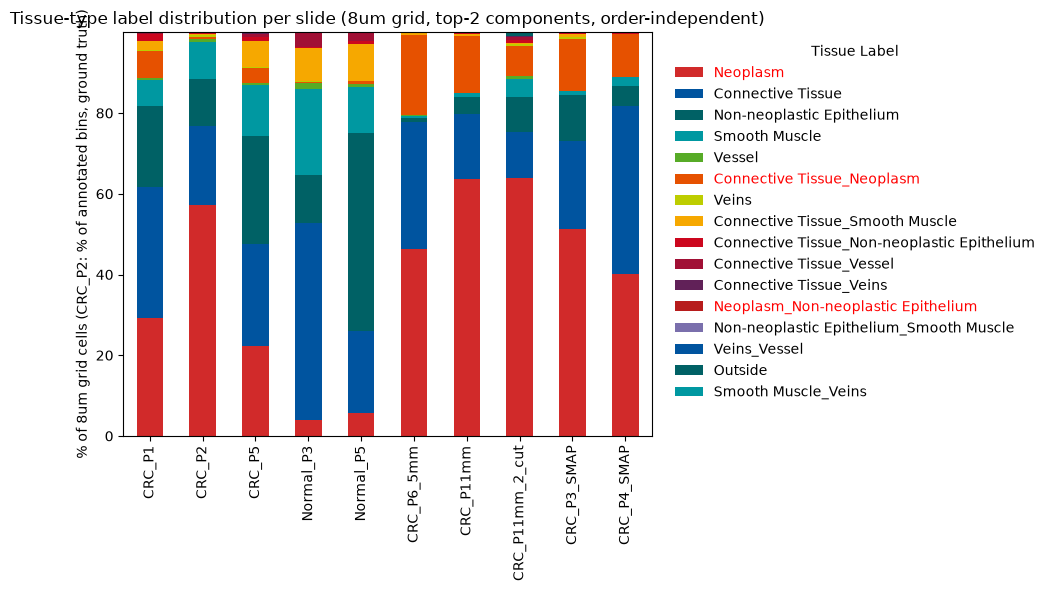

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Bin-level (8um grid) label distribution, all 10 available slides -- CRC_P3_SMAP/
# CRC_P4_SMAP's grid label transfer has already been run (lt.main_grid(), see
# new_single_omics.ipynb), so no recomputation needed here, just reading its output.
def canonical_top2(labels):
    # collapse to top 2 labels (e.g. veins_muscle_vessel and veins_muscle_neoplasm is veins_muscle)
    top2 = labels.astype(str).str.split("_").str[:2]
    return top2.apply(lambda parts: "_".join(sorted(parts)))

grid_gt_008um = lt.aggregate_bin_annotation_to_grid(reference_sample="CRC_P2", group_size=4)  # 4 x 2um = 8um
crc_p2_grid_dist = canonical_top2(grid_gt_008um["annotation"]).value_counts(normalize=True) * 100
crc_p2_grid_dist.name = "CRC_P2"

grid_dist_rows = [crc_p2_grid_dist]
for sample_id in ALL_SAMPLES:
    if sample_id == "CRC_P2":
        continue
    pred_path = label_transfer_dir(sample_id) / f"{sample_id}_grid_predictions.parquet"
    if not pred_path.exists():
        print(f"{sample_id}: no _grid_predictions.parquet yet -- skipping")
        continue
    grid_pred = pd.read_parquet(pred_path, columns=["predicted_tissuetype_grid_image"])
    dist = canonical_top2(grid_pred["predicted_tissuetype_grid_image"]).value_counts(normalize=True) * 100
    dist.name = sample_id
    grid_dist_rows.append(dist)

label_dist_grid = pd.concat(grid_dist_rows, axis=1).T.reindex(ALL_SAMPLES).fillna(0)

# Build custom color palette: assign shades of red to labels containing 'neoplasm', 
# and draw from pl.RWTH_CATEGORICAL for non-neoplasm labels.
labels = label_dist_grid.columns
custom_colors = []

# Shades of red to cycle through for neoplasm categories
red_shades = ["#D12A2A", "#E65100", "#B71C1C", "#FF5252", "#880E4F"]
neoplasm_idx = 0
non_neoplasm_idx = 0

for label in labels:
    if "neoplasm" in str(label).lower():
        custom_colors.append(red_shades[neoplasm_idx % len(red_shades)])
        neoplasm_idx += 1
    else:
        custom_colors.append(pl.RWTH_CATEGORICAL[non_neoplasm_idx % len(pl.RWTH_CATEGORICAL)])
        non_neoplasm_idx += 1

palette = ListedColormap(custom_colors)

# Plotting
ax = label_dist_grid.plot(kind="bar", stacked=True, figsize=(10, 6), colormap=palette)
ax.set_ylabel("% of 8um grid cells (CRC_P2: % of annotated bins, ground truth)")

# 1. Remove x-axis label
ax.set_xlabel("")

ax.set_title("Tissue-type label distribution per slide (8um grid, top-2 components, order-independent)")

# 2. Configure legend and remove frame/border
leg = ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Tissue Label", frameon=False)

# 3. Color legend text containing ''neoplasm' red
for text in leg.get_texts():
    if "neoplasm" in text.get_text().lower():
        text.set_color("red")

plt.tight_layout()
plt.show()

## Transcriptomics

In this first part of the evaluation, we check the preprocessing of the transcriptomics. 
As a first step, we 

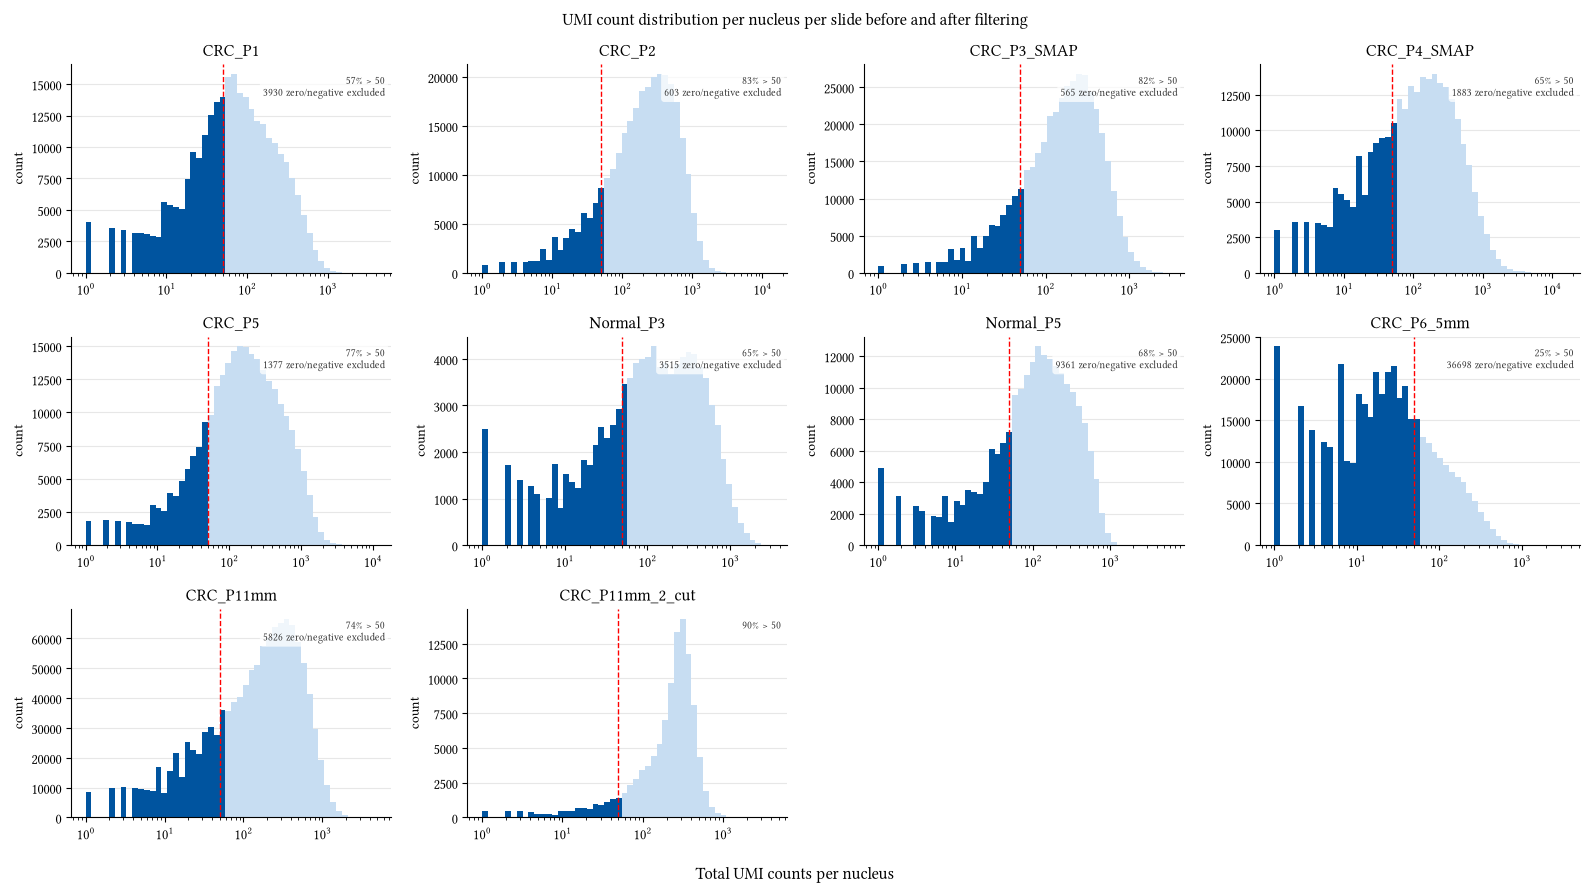

In [9]:
# Plot UMI count distribution for all slides before filtering them out (check CustomBinning.ipynb for the right anndata to load)
import pickle
import geopandas as gpd
from shapely.geometry import Polygon

dir_custom_binning = "01_preprocessing/cell_seg_stardist/002um/custom_binning"
dir_cellseg = "01_preprocessing/cell_seg_stardist/002um"
UMI_CUTOFF = 50   # matches the actual filter applied in CustomBinning.ipynb (total_counts > 50)
AREA_CUTOFF = 500  # matches the actual filter applied in CustomBinning.ipynb (area < 500 px^2)

# nuclei_grouped_UMI_count.h5ad has no total_counts/area saved -- both need to be
# computed here, same as CustomBinning.ipynb does. Area only exists via the raw
# StarDist polygons (polys_FullSection.pckl, per-sample -- no combined equivalent
# for raw segmentation output), joined onto the UMI-count population by id.
# Opens the merged combined/ copy once (backed) and slices one sample at a time
# instead of reading each sample's own per-sample nuclei_grouped_UMI_count.h5ad in
# full, so those per-sample copies are free to delete once preprocessing is done.
grouped_combined = sc.read_h5ad(basedir / "combined" / dir_custom_binning / "nuclei_grouped_UMI_count.h5ad", backed="r")

qc_by_slide = {}
for sample_id in samples:
    adata = grouped_combined[grouped_combined.obs["Slide_ID"] == sample_id].to_memory()
    sc.pp.calculate_qc_metrics(adata, percent_top=None, inplace=True)

    with open(basedir / sample_id / dir_cellseg / "polys_FullSection.pckl", "rb") as f:
        polys = pickle.load(f)
    geometries = [Polygon([(y, x) for x, y in zip(c[0], c[1])]) for c in polys["coord"]]
    gdf = gpd.GeoDataFrame({"id": [f"ID_{i+1}" for i in range(len(geometries))], "area": gpd.GeoSeries(geometries).area})

    qc_by_slide[sample_id] = adata.obs[["id", "total_counts", "n_genes_by_counts"]].merge(gdf, on="id", how="left")
    del adata, polys, geometries, gdf
    gc.collect()
del grouped_combined
gc.collect()

pl.plot_distribution_grid(
    {s: df["total_counts"].to_numpy() for s, df in qc_by_slide.items()},
    xlabel="Total UMI counts per nucleus",
    title="UMI count distribution per nucleus per slide before and after filtering",
    cutoff=UMI_CUTOFF,
    log_x=True,
)

plt.savefig("output/umi_counts_nuclei_distribution.pdf")
plt.show()

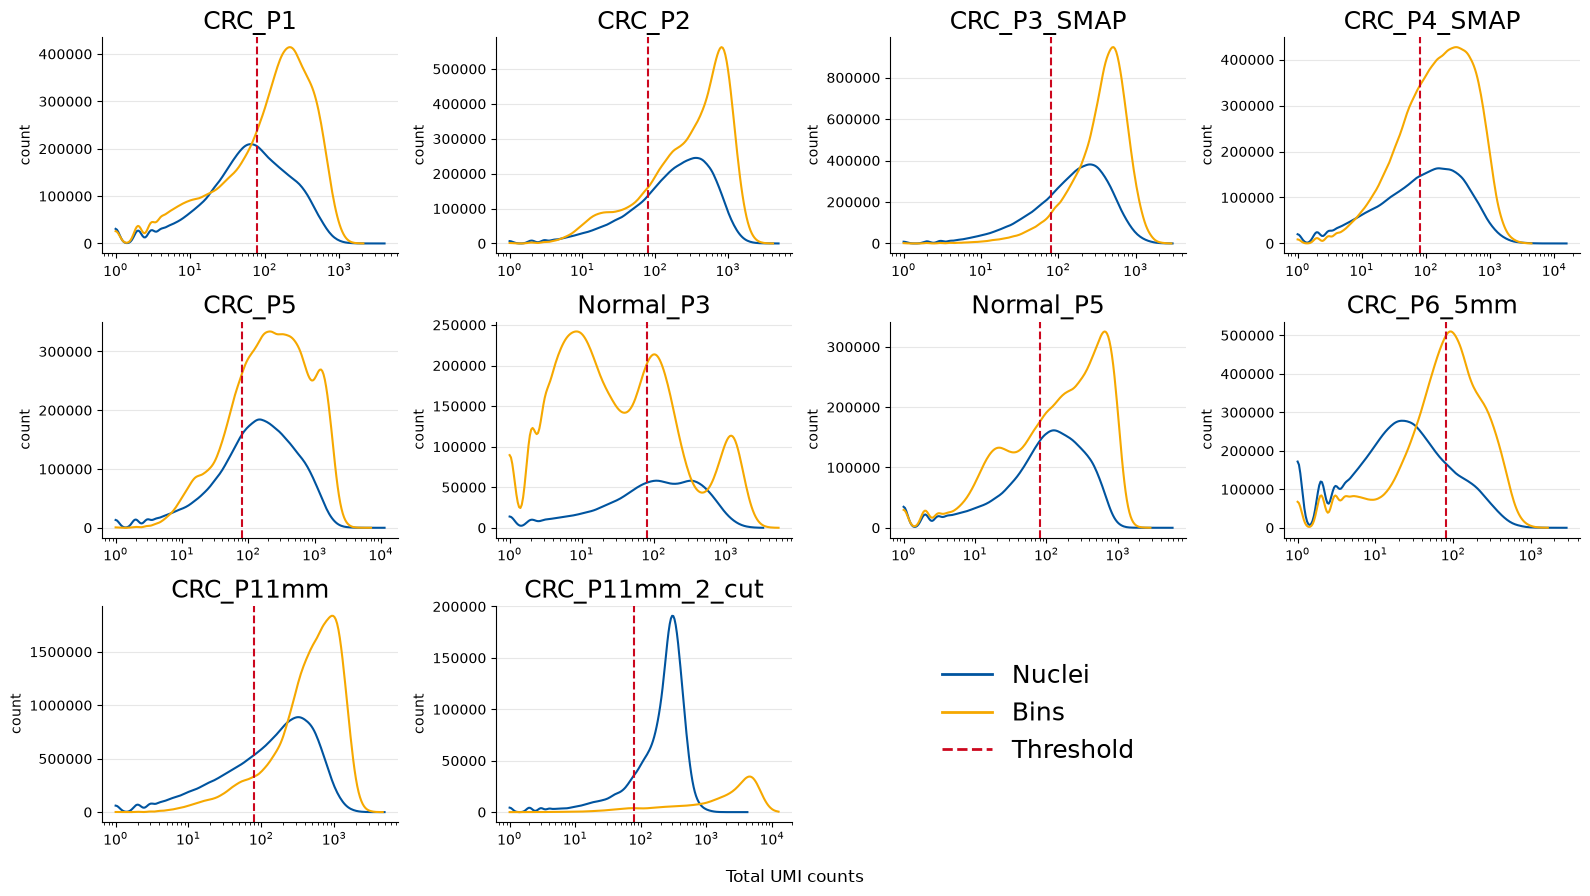

In [5]:
from scipy.stats import gaussian_kde

dir_custom_binning = "01_preprocessing/cell_seg_stardist/002um/custom_binning"
dir_cellseg = "01_preprocessing/cell_seg_stardist/002um"
dir_custom_binning_bins = "01_preprocessing/grid_bin/008um/custom_binning"
UMI_CUTOFF = 80
AREA_CUTOFF = 500

NUCLEI_COLOR = pl.RWTH_BLUE_RAMP[0]         # blue
BINS_COLOR = pl.RWTH_ACCENT_COLORS[4]       # "#F6A800" -- RWTH orange, same as the cutoff-highlight color used in the cell above
THRESHOLD_COLOR = pl.RWTH_ACCENT_COLORS[5]  # red

_rng = np.random.default_rng(0)
KDE_MAX_POINTS = 200_000  # bin counts run into the millions -- subsample for KDE fitting/eval speed

def plot_umi_kde(values, ax, color):
    values = np.asarray(values)
    values = values[values > 0]
    n_true = len(values)  # scale by the REAL count, not the subsample, so the y-axis reflects true population size
    if n_true > KDE_MAX_POINTS:
        values = _rng.choice(values, KDE_MAX_POINTS, replace=False)
    if len(values) < 2 or np.ptp(values) == 0:
        return
    log_values = np.log10(values)
    kde = gaussian_kde(log_values)
    x_grid = np.linspace(log_values.min(), log_values.max(), 200)
    ax.plot(10 ** x_grid, kde(x_grid) * n_true, color=color, linewidth=1.5)

# 8x8um grid-grouped counts (raw, no QC/count-area filter -- same pipeline stage as
# qc_by_slide's own nuclei_grouped_UMI_count.h5ad, just for grid bins instead of nuclei
# polygons; see aggregate_grid_bin_UMI_count.py). Replaces filtered_custom_bins.h5ad's
# raw UNGROUPED 2um bins, which weren't actually comparable to nuclei's aggregated totals.
bins_adata = ad.read_h5ad(
    basedir / "combined" / dir_custom_binning_bins / "nuclei_grouped_UMI_count.h5ad", backed="r"
)

ncols, nrows = 4, 3
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes_flat = axes.flatten()

for ax, sample_id in zip(axes_flat, samples):
    df = qc_by_slide[sample_id]
    # Full nuclei population (not pre-restricted to total_counts > UMI_CUTOFF) -- using the
    # already-filtered subset here would make this line start exactly AT the cutoff by
    # construction (there's nothing below it left to plot), which is what was happening
    # before: not a bug, just the wrong population for a "where does the cutoff fall"
    # comparison. This matches "Total Nuclei" from the summary table above, not "Filtered
    # Nuclei" -- the bins line below is now the same pipeline stage (raw, pre-QC grid-grouped
    # counts), so both lines stay on equal footing.
    nuclei_umi = df["total_counts"].to_numpy()
    plot_umi_kde(nuclei_umi, ax, NUCLEI_COLOR)

    bin_mask = (bins_adata.obs["Slide_ID"] == sample_id).to_numpy()
    bins_sub = bins_adata[bin_mask].to_memory()
    bins_umi = np.asarray(bins_sub.X.sum(axis=1)).ravel()
    plot_umi_kde(bins_umi, ax, BINS_COLOR)
    del bins_sub
    gc.collect()

    ax.axvline(UMI_CUTOFF, color=THRESHOLD_COLOR, linestyle="--", linewidth=1.5)
    ax.set_xscale("log")
    ax.set_ylabel("count")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.3)
    ax.ticklabel_format(style="plain", axis="y")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_title(sample_id, fontsize=18)

del bins_adata
gc.collect()

for j in range(len(samples), len(axes_flat)):
    axes_flat[j].axis("off")

legend_ax = axes_flat[len(samples)]
legend_ax.axis("on")
legend_ax.set_xticks([]); legend_ax.set_yticks([])
for spine in legend_ax.spines.values():
    spine.set_visible(False)
legend_handles = [
    plt.Line2D([0], [0], color=NUCLEI_COLOR, linewidth=2, label="Nuclei"),
    plt.Line2D([0], [0], color=BINS_COLOR, linewidth=2, label="Bins"),
    plt.Line2D([0], [0], color=THRESHOLD_COLOR, linewidth=2, linestyle="--", label="Threshold"),
]
legend_ax.legend(handles=legend_handles, loc="center", frameon=False, fontsize=18)

fig.supxlabel("Total UMI counts")
fig.tight_layout()
plt.show()


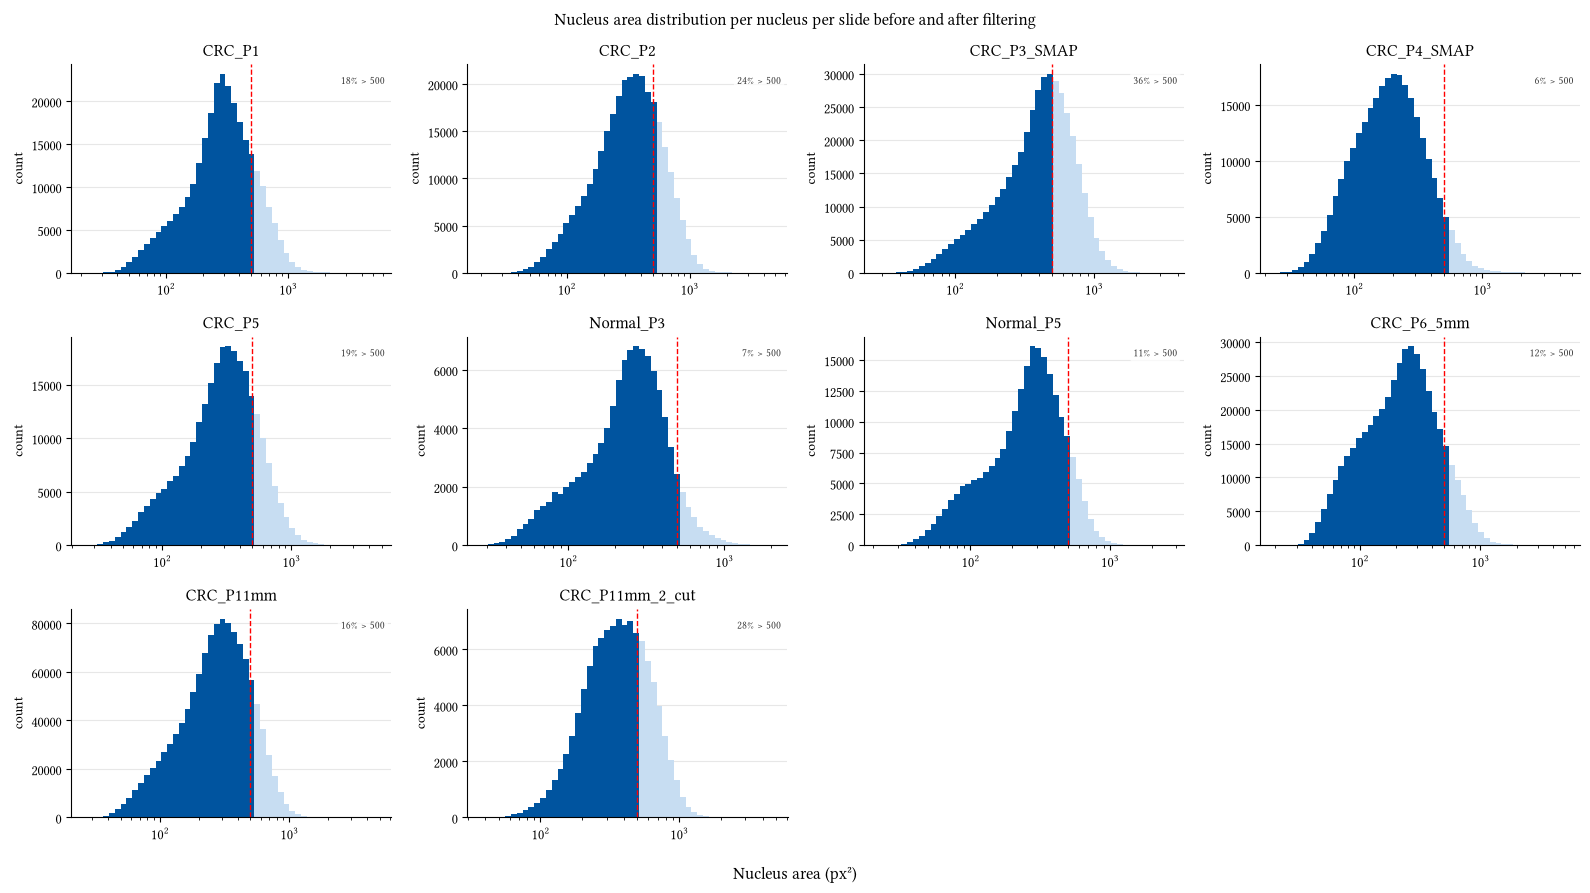

In [10]:
# Plot cell size distribution for all slides before filtering them out (check CustomBinning.ipynb for the right anndata to load)
pl.plot_distribution_grid(
    {s: df["area"].to_numpy() for s, df in qc_by_slide.items()},
    xlabel="Nucleus area (px²)",
    title="Nucleus area distribution per nucleus per slide before and after filtering",
    cutoff=AREA_CUTOFF,
    log_x=True,
)
plt.savefig("output/size_nuclei_distribution.pdf")
plt.show()


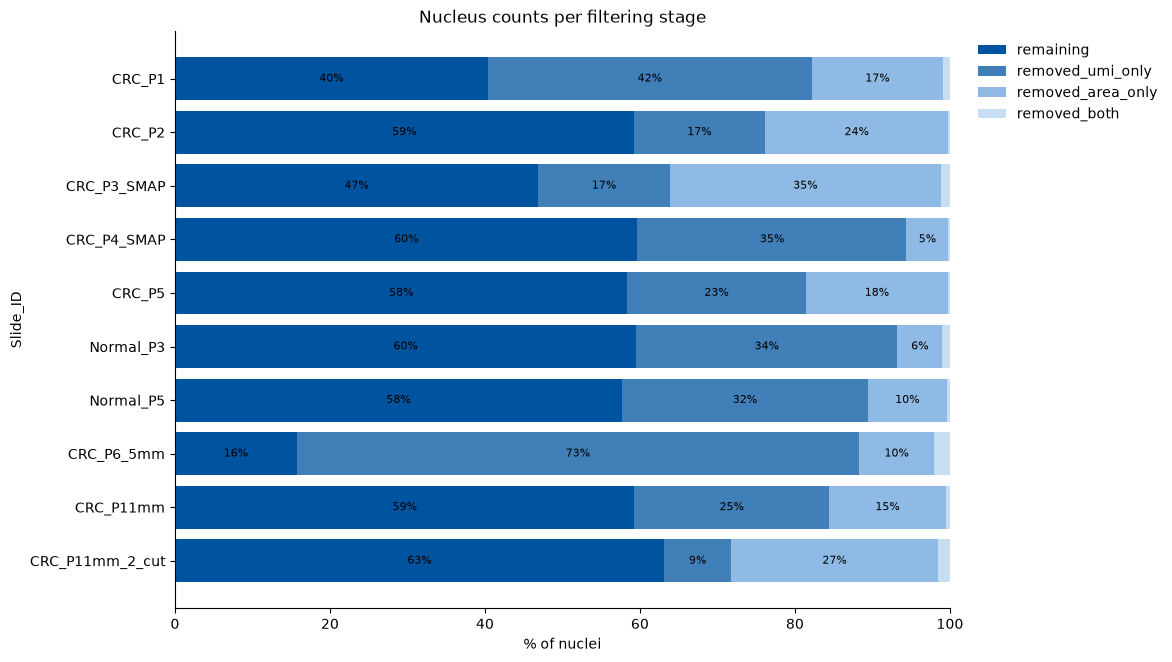

,remaining,removed_umi_only,removed_area_only,removed_both
Slide_ID,,,,
CRC_P1,116787,121004,48979,2635
CRC_P2,180890,51734,72318,678
CRC_P3_SMAP,199039,72184,148599,5048
CRC_P4_SMAP,165241,96128,14858,676
CRC_P5,158117,62436,49663,762
Normal_P3,61849,35007,6049,1034
Normal_P5,130098,71611,22972,951
CRC_P6_5mm,72097,333155,44661,9341
CRC_P11mm,708267,300366,180228,6343


In [8]:
# plot cell count per slide:
# 1. total before filtering
# 2. removed through UMI filter
# 3. removed through size filter
# 4. total left
funnel_rows = []
for sample_id, df in qc_by_slide.items():
    fail_umi = df["total_counts"] <= UMI_CUTOFF
    fail_area = df["area"] >= AREA_CUTOFF
    funnel_rows.append({
        "Slide_ID": sample_id,
        "remaining": (~fail_umi & ~fail_area).sum(),
        "removed_umi_only": (fail_umi & ~fail_area).sum(),
        "removed_area_only": (~fail_umi & fail_area).sum(),
        "removed_both": (fail_umi & fail_area).sum(),
    })

funnel_df = pd.DataFrame(funnel_rows).set_index("Slide_ID")
pl.plot_filter_funnel(funnel_df, title="Nucleus counts per filtering stage")
plt.savefig("output/Nucleus_counts_per_filtering_stage.pdf")
plt.show()
funnel_df


In [9]:
# Nuclei- and bin-level filtering funnel per slide, alongside the disease prediction
# from cell 6. Total/Filtered Nuclei reuse qc_by_slide/funnel_df from the cell above.
# Total Bins is the raw 002um Visium HD bin count per slide (tissue_positions.parquet,
# in_tissue==1); Filtered Bins is filtered_custom_bins.h5ad's count per slide --
# CustomBinning.ipynb's tissue + single-nucleus-polygon filter applied to those bins.
total_bins = pd.Series(
    {
        sample_id: pd.read_parquet(
            basedir / sample_id / "output/binned_outputs/square_002um/spatial/tissue_positions.parquet",
            columns=["in_tissue"],
        )["in_tissue"].sum()
        for sample_id in samples
    },
    name="Total Bins",
)

filtered_bins_adata = ad.read_h5ad(
    basedir / "combined" / dir_custom_binning / "filtered_custom_bins.h5ad", backed="r"
)
filtered_bins = filtered_bins_adata.obs["Slide_ID"].value_counts()
del filtered_bins_adata

nuclei_bins_summary = pd.DataFrame({
    "Total Nuclei": {sample_id: len(qc_by_slide[sample_id]) for sample_id in samples},
    "Filtered Nuclei": funnel_df["remaining"],
    "Total Bins": total_bins,
    "Filtered Bins": filtered_bins,
    "Predicted Diseased (%)": summary["predicted_diseased_tissue_pct"],
}).reindex(samples)
nuclei_bins_summary.index.name = "Slide_ID"

nuclei_bins_summary

,Total Nuclei,Filtered Nuclei,Total Bins,Filtered Bins,Predicted Diseased (%)
Slide_ID,,,,,
CRC_P1,289405,116787,8115564,1815121,44.612374
CRC_P2,305620,180890,8731400,2131694,NaN
CRC_P3_SMAP,424870,199039,10366733,3240006,NaN
CRC_P4_SMAP,276903,165241,10170511,2249177,NaN
CRC_P5,270978,158117,8665632,1721517,33.875568
Normal_P3,103939,61849,7793528,522423,2.629040
Normal_P5,225632,130098,6873423,1212749,6.176361
CRC_P6_5mm,459254,72097,9393726,2344707,70.399709
CRC_P11mm,1195204,708267,27477504,7107405,89.569078


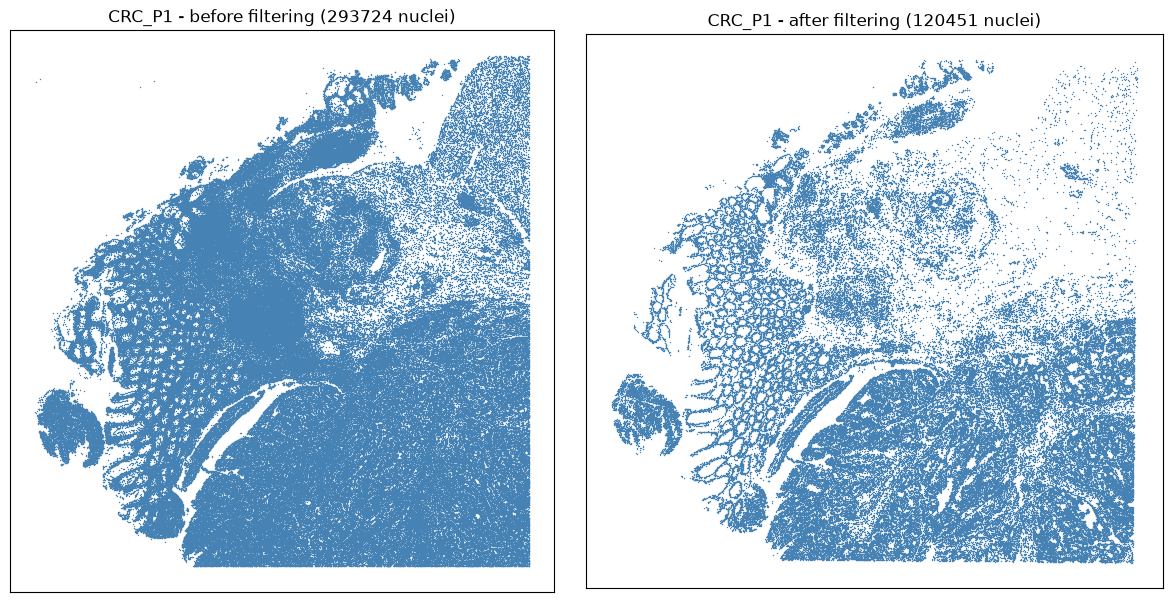

763

In [10]:
# for a chosen cell: plot all cells (dots can all have the same color) based on their spatial coordinates
# - befire filtering
# - after filtering
sample_trans = samples[0]  # change to inspect a different slide

with open(basedir / sample_trans / dir_cellseg / "polys_FullSection.pckl", "rb") as f:
    polys = pickle.load(f)
geometries = [Polygon([(y, x) for x, y in zip(c[0], c[1])]) for c in polys["coord"]]
before_centroids = gpd.GeoSeries(geometries).centroid
before_coords = np.stack([before_centroids.x.to_numpy(), before_centroids.y.to_numpy()], axis=1)

# Restrict "before filtering" to nuclei within the valid barcoding range (tissue_positions.parquet),
# same bounding box CustomBinning.ipynb uses for its own ROI plots -- excludes nuclei that fall
# outside where the Visium HD barcode grid actually has valid (mapped) positions.
tissue_positions = pd.read_parquet(basedir / sample_trans / "output/binned_outputs/square_002um/spatial/tissue_positions.parquet")
valid = tissue_positions.loc[tissue_positions["pxl_col_in_fullres"] > 0, ["pxl_col_in_fullres", "pxl_row_in_fullres"]]
x_min, x_max = valid["pxl_col_in_fullres"].min(), valid["pxl_col_in_fullres"].max()
y_min, y_max = valid["pxl_row_in_fullres"].min(), valid["pxl_row_in_fullres"].max()
in_range = (
    (before_coords[:, 0] >= x_min) & (before_coords[:, 0] <= x_max) &
    (before_coords[:, 1] >= y_min) & (before_coords[:, 1] <= y_max)
)
before_coords = before_coords[in_range]

# Reads the merged combined/ copy (filtered to this sample) instead of this sample's own
# per-sample count_area_filtered_adata.h5ad, so per-sample copies are free to delete.
after_combined = sc.read_h5ad(basedir / "combined" / dir_custom_binning / "count_area_filtered_adata.h5ad", backed="r")
after_coords = np.asarray(after_combined[after_combined.obs["Slide_ID"] == sample_trans].to_memory().obsm["spatial"])
del after_combined

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
pl.plot_spatial_points(before_coords, ax=axes[0], title=f"{sample_trans} - before filtering ({len(before_coords)} nuclei)")
pl.plot_spatial_points(after_coords, ax=axes[1], title=f"{sample_trans} - after filtering ({len(after_coords)} nuclei)")
plt.tight_layout()
plt.savefig("output/CRC_P1_before_and_after_nuclei_filtering.pdf")
plt.show()

del polys, geometries, before_centroids, tissue_positions
gc.collect()

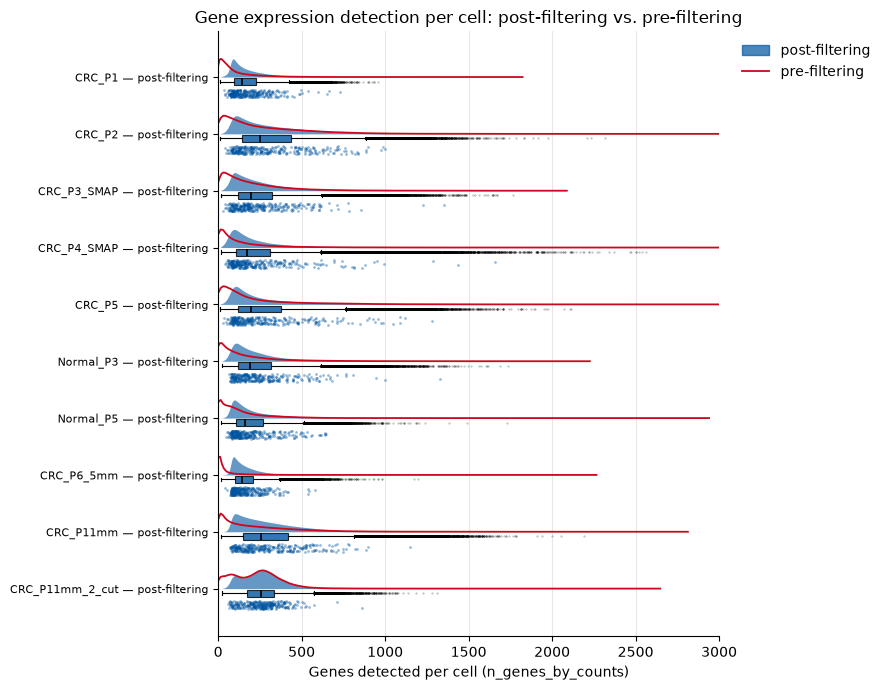

In [11]:
# Gene expression distribution per cell: how many genes are detected (nonzero) per cell,
# pre- vs. post-filtering, per slide. Pre-filtering reuses n_genes_by_counts already
# computed in qc_by_slide (cell above); post-filtering comes straight from the merged
# combined/ count_area_filtered_adata.h5ad (filtered per sample), which already has it
# saved -- .obs is loaded fully even in backed mode, so no per-sample file/to_memory needed.
genes_by_slide = {}
count_area_combined = sc.read_h5ad(basedir / "combined" / dir_custom_binning / "count_area_filtered_adata.h5ad", backed="r")
for sample_id in samples:
    post = count_area_combined.obs.loc[count_area_combined.obs["Slide_ID"] == sample_id, "n_genes_by_counts"]
    genes_by_slide[sample_id] = {
        "pre-filtering": qc_by_slide[sample_id]["n_genes_by_counts"].to_numpy(),
        "post-filtering": post.to_numpy(),
    }
del count_area_combined

# One row per slide (post-filtering's full cloud+box+rain, in blue), with
# pre-filtering overlaid as a red density line on the same row instead of its
# own separate cloud+box+rain -- shows the filtering shift directly, in one plot.
XLIM = (0, 3000)
ax = pl.plot_raincloud_grid(
    {sample_id: {"post-filtering": stages["post-filtering"]} for sample_id, stages in genes_by_slide.items()},
    xlabel="Genes detected per cell (n_genes_by_counts)",
    title="Gene expression detection per cell: post-filtering vs. pre-filtering",
    xlim=XLIM,
)

from scipy.stats import gaussian_kde
PRE_FILTER_COLOR = pl.RWTH_ACCENT_COLORS[5]  # red
n_rows = len(genes_by_slide)
for i, (sample_id, stages) in enumerate(genes_by_slide.items()):
    y0 = n_rows - i  # matches plot_raincloud_grid's own top-to-bottom row placement
    pre_values = stages["pre-filtering"]
    pre_values = pre_values[np.isfinite(pre_values)]
    if len(pre_values) < 2 or np.ptp(pre_values) == 0:
        continue
    kde = gaussian_kde(pre_values)
    grid_max = min(pre_values.max(), XLIM[1])
    x_grid = np.linspace(pre_values.min(), grid_max, 200)
    density = kde(x_grid)
    density = density / density.max() * 0.32  # same scaling plot_raincloud_grid uses for its cloud
    ax.plot(x_grid, y0 + density, color=PRE_FILTER_COLOR, linewidth=1.3)

# plot_raincloud_grid already drew its own single-stage legend (post-filtering only) --
# replace it with one covering both, rather than layering a second legend on top.
post_color = pl.RWTH_CATEGORICAL[0]
legend_handles = [plt.Rectangle((0, 0), 1, 1, color=post_color, alpha=0.7),
                  plt.Line2D([0], [0], color=PRE_FILTER_COLOR, linewidth=1.3)]
ax.legend(legend_handles, ["post-filtering", "pre-filtering"],
          bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.savefig("output/Nucleus_gene_expression_distribution.pdf")
plt.show()

### SVG distribution & cross-slide comparison
Addresses the two remaining TODO items above. Follows a 3-level breakdown (per-slide burden -> cross-slide reproducibility -> healthy-vs-diseased repertoire), reusing the SVG union already computed by the autoencoder pipeline (`functions.dual_autoencoder.get_svg_union_mask`, ~539 genes -- flagged as spatially variable, Moran's I FDR-corrected p < 0.05 and I > 0.1, in at least one of the 10 slides) rather than recomputing SVG calling here. All numbers below come from `data/combined/.../count_area_filtered_adata.h5ad`'s `varm['moranI_per_sample']` / `varm['moranI_pval_fdr_per_sample']` / `varm['spatially_variable_per_sample']` (column order given by `uns['sample_order']`) -- the same per-slide Moran's I matrices `get_svg.py` / `CustomBinning.ipynb`'s merge step already produced, so SVG-calling parameters (bin size, QC filtering, neighbor graph, FDR threshold) are guaranteed consistent across slides by construction.

**`svg_long` columns**: `gene` -- the gene symbol (one of the 539 union genes). `Slide_ID` / `condition` -- which slide/CRC-or-Normal this row's Moran's I was computed on (one row per gene-slide *pair*, so each gene has 10 rows -- `svg_long.head()` only shows the first gene's first 5 rows, i.e. its first 5 slides in `sample_order`; that's a display truncation, not a real restriction to those slides -- all 10 are in there and used throughout). `moranI` / `moranI_pval_fdr` -- that gene-slide's Moran's I statistic and FDR-corrected p-value. `is_svg` -- whether *this slide* individually called the gene spatially variable (I > 0.1 and FDR p < 0.05); a gene is in the 539-gene union if `is_svg` is True for at least one slide, which is what the prevalence/reproducibility analysis below is built on.

**Moran's I** measures spatial autocorrelation: whether nearby bins/cells have similar expression (near 0 = spatially random, near 1 = strongly clustered/patterned, negative = checkerboard-like). It's the actual statistic SVG calling thresholds on. Plotting its full per-slide *distribution* (section A, over all 18085 tested genes, not just the 539-gene union) is a QC check independent of the fixed 0.1/FDR<0.05 cutoff: it shows whether a slide's overall spatial-structure profile looks like the others, e.g. a slide with a systematically shifted distribution could be flagged even before individual SVG counts diverge.

In [12]:
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
from scipy.spatial.distance import pdist, squareform

from functions.dual_autoencoder import get_svg_union_mask

dir_custom_binning = "01_preprocessing/cell_seg_stardist/002um/custom_binning"
trans_combined = sc.read_h5ad(
    basedir / "combined" / dir_custom_binning / "count_area_filtered_adata.h5ad", backed="r"
)

sample_order = list(trans_combined.uns["sample_order"])
conditions = {s: lt.get_disease_status(s) for s in sample_order}  # "CRC" or "Normal"

svg_union_mask = get_svg_union_mask(trans_combined)
svg_genes = trans_combined.var_names[svg_union_mask].to_numpy()

moranI = np.asarray(trans_combined.varm["moranI_per_sample"])[svg_union_mask]
moranI_fdr = np.asarray(trans_combined.varm["moranI_pval_fdr_per_sample"])[svg_union_mask]
is_svg = np.asarray(trans_combined.varm["spatially_variable_per_sample"])[svg_union_mask].astype(bool)

# long-form table: one row per (gene, slide), restricted to the union -- the
# "feature universe" for everything below, avoids ever plotting all 18k tested genes
svg_long = pd.DataFrame({
    "gene": np.repeat(svg_genes, len(sample_order)),
    "Slide_ID": np.tile(sample_order, len(svg_genes)),
})
svg_long["condition"] = svg_long["Slide_ID"].map(conditions)
svg_long["moranI"] = moranI.ravel()
svg_long["moranI_pval_fdr"] = moranI_fdr.ravel()
svg_long["is_svg"] = is_svg.ravel()

print(f"SVG union: {len(svg_genes)} genes across {len(sample_order)} slides "
      f"({sum(c == 'CRC' for c in conditions.values())} CRC / "
      f"{sum(c == 'Normal' for c in conditions.values())} Normal)")
svg_long.head()

/beegfs/home/cwolf/miniconda3/envs/autoencoder/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/beegfs/home/cwolf/miniconda3/envs/autoencoder/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/beegfs/home/cwolf/miniconda3/envs/autoencoder/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


SVG union: 714 genes across 10 slides (8 CRC / 2 Normal)


,gene,Slide_ID,condition,moranI,moranI_pval_fdr,is_svg
0,ISG15,Normal_P3,Normal,0.132749,0.002546,True
1,ISG15,CRC_P1,CRC,0.028569,0.002867,False
2,ISG15,CRC_P2,CRC,0.077765,0.001792,False
3,ISG15,CRC_P5,CRC,0.021065,0.001841,False
4,ISG15,Normal_P5,Normal,0.002269,0.088083,False


#### A. SVG burden per slide
Before comparing slide-to-slide, check whether SVG counts track QC/coverage rather than biology -- a slide with more cells or higher sequencing depth can produce more significant genes independent of tissue.

In [13]:
# per-slide burden table: tested genes, SVG count/fraction, effect-size and
# significance summaries (over ALL 18085 tested genes, not just the union --
# the union would bias median/max upward by construction), plus QC covariates
# so a high/low SVG count can be sanity-checked against coverage
all_moranI = np.asarray(trans_combined.varm["moranI_per_sample"])
all_moranI_fdr = np.asarray(trans_combined.varm["moranI_pval_fdr_per_sample"])
all_is_svg = np.asarray(trans_combined.varm["spatially_variable_per_sample"]).astype(bool)

n_tested = (~np.isnan(all_moranI)).sum(axis=0)
n_svg = all_is_svg.sum(axis=0)
median_I = np.nanmedian(all_moranI, axis=0)
max_I = np.nanmax(all_moranI, axis=0)
median_neg_log10_q = np.nanmedian(-np.log10(np.clip(all_moranI_fdr, 1e-300, None)), axis=0)

qc_per_slide = trans_combined.obs[["Slide_ID", "total_counts", "n_genes_by_counts"]].groupby(
    "Slide_ID", observed=True
).agg(
    n_cells=("total_counts", "size"),
    median_total_counts=("total_counts", "median"),
    median_n_genes=("n_genes_by_counts", "median"),
).reindex(sample_order)

svg_summary = pd.DataFrame({
    "Slide_ID": sample_order,
    "condition": [conditions[s] for s in sample_order],
    "n_tested_genes": n_tested,
    "n_svg": n_svg,
    "frac_svg": n_svg / n_tested,
    "median_moranI": median_I,
    "max_moranI": max_I,
    "median_neg_log10_q": median_neg_log10_q,
}).set_index("Slide_ID").join(qc_per_slide).sort_values("n_svg", ascending=False)

svg_summary

,condition,n_tested_genes,n_svg,frac_svg,median_moranI,max_moranI,median_neg_log10_q,n_cells,median_total_counts,median_n_genes
Slide_ID,,,,,,,,,,
CRC_P4_SMAP,CRC,16568,309,0.018650,0.004884,0.793875,2.763021,151437,242.0,172.0
Normal_P3,Normal,17901,298,0.016647,0.004240,0.758339,1.623214,57187,261.0,193.0
CRC_P5,CRC,18047,281,0.015570,0.004504,0.656690,2.734962,176903,254.0,197.0
CRC_P2,CRC,18057,247,0.013679,0.004268,0.792806,2.746619,224825,297.0,253.0
CRC_P3_SMAP,CRC,18008,235,0.013050,0.003422,0.809402,2.733721,295977,237.0,197.0
Normal_P5,Normal,18050,164,0.009086,0.002905,0.620818,1.658083,127584,205.0,162.0
CRC_P1,CRC,17990,163,0.009061,0.002411,0.804814,1.340286,120451,176.0,143.0
CRC_P11mm,CRC,17623,124,0.007036,0.002633,0.607921,2.789298,785828,287.0,258.0
CRC_P11mm_2_cut,CRC,17903,120,0.006703,0.002407,0.724328,1.196004,89110,279.0,258.0


Here, we assess the SVG count for all slides with nuclei as the unit.

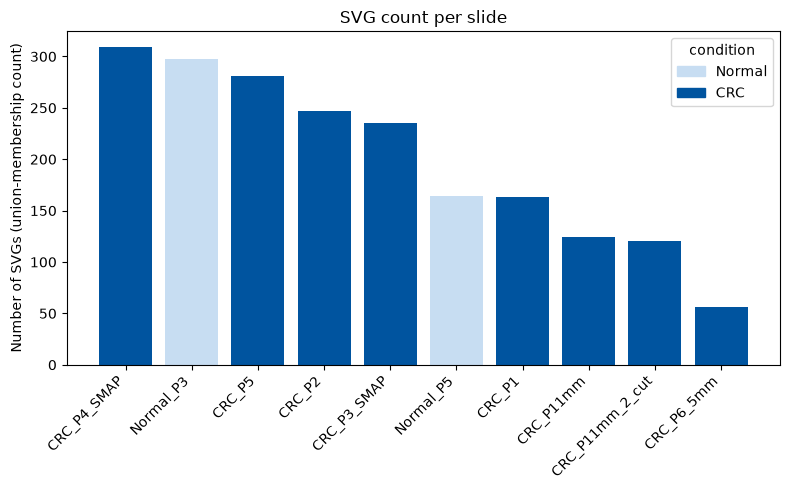

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = {"Normal": pl.RWTH_BLUE_RAMP[3], "CRC": pl.RWTH_BLUE_RAMP[0]}  # blue first, then red
bars = svg_summary["n_svg"]
ax.bar(bars.index, bars.values, color=[colors[c] for c in svg_summary["condition"]])
ax.set_ylabel("Number of SVGs (union-membership count)")
ax.set_title("SVG count per slide")
ax.tick_params(axis="x", rotation=45)
for label in ax.get_xticklabels():
    label.set_ha("right")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in colors.items()], title="condition")
plt.tight_layout()
plt.show()

Next, we also assess the SVG count for all slides, but with bins as the unit.

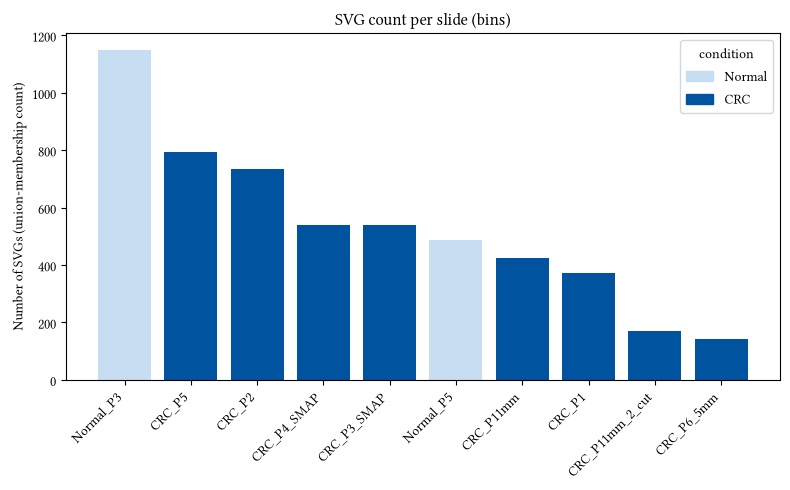

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

sys.path.insert(0, str(Path("..").resolve()))
from functions import plotting as pl
from functions import label_transfer as lt

basedir = Path("../data")
dir_custom_binning_bins = "01_preprocessing/grid_bin/008um/custom_binning"

bins_combined = sc.read_h5ad(
    basedir / "combined" / dir_custom_binning_bins / "count_area_filtered_adata.h5ad", backed="r"
)
sample_order = list(bins_combined.uns["sample_order"])
conditions = {s: lt.get_disease_status(s) for s in sample_order}

# Over ALL tested genes, not just an SVG union -- same convention the nuclei
# version uses (a union would bias this upward by construction).
all_is_svg = np.asarray(bins_combined.varm["spatially_variable_per_sample"]).astype(bool)
n_svg = all_is_svg.sum(axis=0)

svg_summary_bins = pd.DataFrame({
    "Slide_ID": sample_order,
    "condition": [conditions[s] for s in sample_order],
    "n_svg": n_svg,
}).set_index("Slide_ID").sort_values("n_svg", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
colors = {"Normal": pl.RWTH_BLUE_RAMP[3], "CRC": pl.RWTH_BLUE_RAMP[0]}
bars = svg_summary_bins["n_svg"]
ax.bar(bars.index, bars.values, color=[colors[c] for c in svg_summary_bins["condition"]])
ax.set_ylabel("Number of SVGs (union-membership count)")
ax.set_title("SVG count per slide (bins)")
ax.tick_params(axis="x", rotation=45)
for label in ax.get_xticklabels():
    label.set_ha("right")
ax.legend(handles=[Patch(color=c, label=k) for k, c in colors.items()], title="condition")
plt.tight_layout()
plt.show()


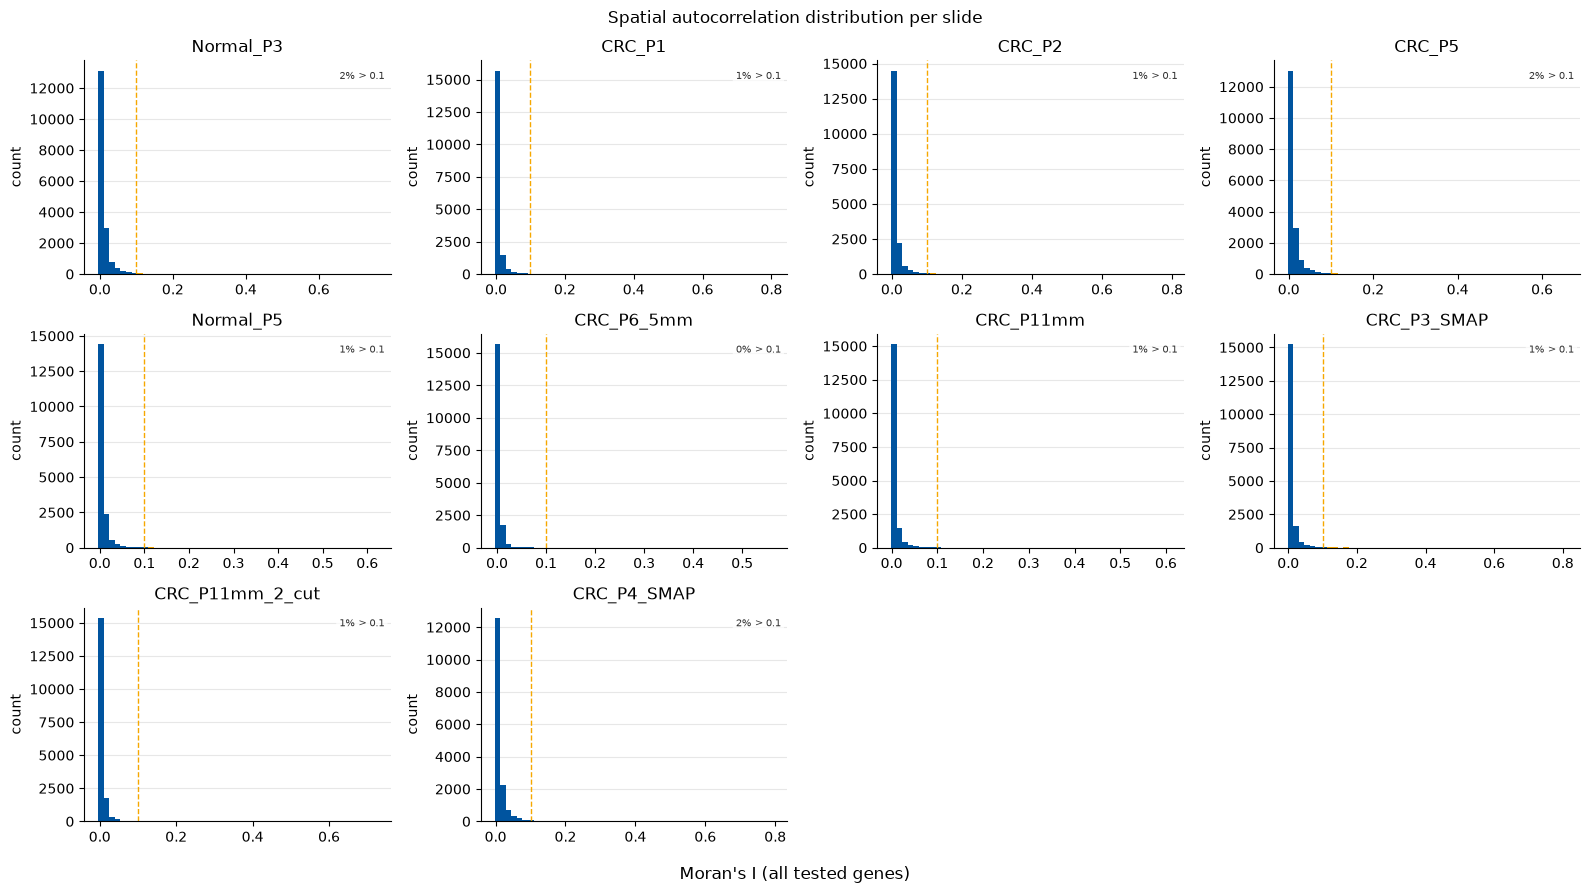

In [15]:
# Moran's I distribution per slide, over ALL tested genes (not just the SVG union) --
# shows whether a slide's overall spatial-autocorrelation profile looks like the others,
# independent of the fixed 0.1/FDR<0.05 cutoff used to call individual genes SVGs.
pl.plot_distribution_grid(
    {s: all_moranI[:, i][~np.isnan(all_moranI[:, i])] for i, s in enumerate(sample_order)},
    xlabel="Moran's I (all tested genes)",
    title="Spatial autocorrelation distribution per slide",
    cutoff=0.1,
    log_x=False,
)
plt.savefig("output/Moran's I distribution per slide, over ALL tested genes.pdf")
plt.show()

#### B. SVG reproducibility across slides
Which SVGs are shared, and which are slide-specific? `upsetplot` isn't in this environment, so set membership is summarized with prevalence-threshold categories instead of a true UpSet plot (`pip install upsetplot` would enable one if useful later -- the categories below answer the same question).

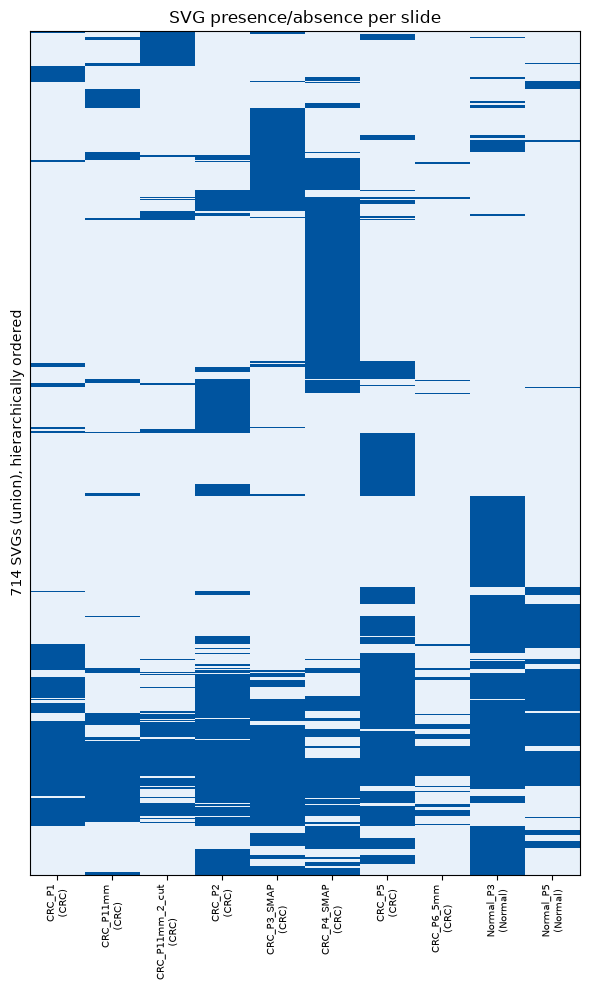

In [16]:
# binary presence heatmap: genes (rows) x slides (columns), rows ordered by
# hierarchical clustering on co-occurrence so reproducible blocks are visible;
# columns grouped by condition rather than interleaved
presence = is_svg.astype(float)  # (n_genes, n_samples), same row order as svg_genes
order = sorted(range(len(sample_order)), key=lambda i: (conditions[sample_order[i]], sample_order[i]))
presence_ordered = presence[:, order]
cols_ordered = [sample_order[i] for i in order]

row_linkage = linkage(presence_ordered, method="average", metric="jaccard")
row_order = leaves_list(row_linkage)

fig, ax = plt.subplots(figsize=(6, 10))
ax.imshow(presence_ordered[row_order], aspect="auto", cmap=pl.rwth_blue_cmap(), interpolation="none")
ax.set_xticks(range(len(cols_ordered)))
ax.set_xticklabels(
    [f"{s}\n({conditions[s]})" for s in cols_ordered], rotation=90, fontsize=7
)
ax.set_yticks([])
ax.set_ylabel(f"{len(svg_genes)} SVGs (union), hierarchically ordered")
ax.set_title("SVG presence/absence per slide")
plt.tight_layout()
plt.savefig("output/heatmap_svg_dist_per_slide.pdf")
plt.show()

/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


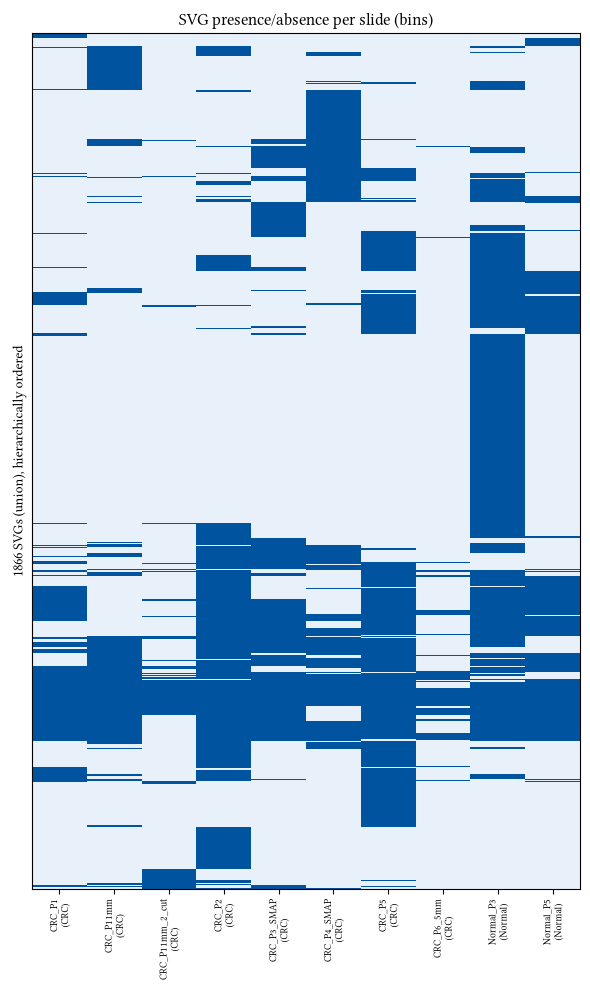

In [2]:
import sys
from pathlib import Path
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list

sys.path.insert(0, str(Path("..").resolve()))
from functions import plotting as pl
from functions import label_transfer as lt
from functions.dual_autoencoder import get_svg_union_mask

basedir = Path("../data")
dir_custom_binning_bins = "01_preprocessing/grid_bin/008um/custom_binning"

bins_combined = sc.read_h5ad(
    basedir / "combined" / dir_custom_binning_bins / "count_area_filtered_adata.h5ad", backed="r"
)
sample_order_bins = list(bins_combined.uns["sample_order"])
conditions_bins = {s: lt.get_disease_status(s) for s in sample_order_bins}

svg_union_mask_bins = get_svg_union_mask(bins_combined)
svg_genes_bins = bins_combined.var_names[svg_union_mask_bins].to_numpy()
is_svg_bins = np.asarray(bins_combined.varm["spatially_variable_per_sample"])[svg_union_mask_bins].astype(bool)

# binary presence heatmap: genes (rows) x slides (columns), rows ordered by
# hierarchical clustering on co-occurrence so reproducible blocks are visible;
# columns grouped by condition rather than interleaved
presence = is_svg_bins.astype(float)  # (n_genes, n_samples), same row order as svg_genes_bins
order = sorted(range(len(sample_order_bins)), key=lambda i: (conditions_bins[sample_order_bins[i]], sample_order_bins[i]))
presence_ordered = presence[:, order]
cols_ordered = [sample_order_bins[i] for i in order]

row_linkage = linkage(presence_ordered, method="average", metric="jaccard")
row_order = leaves_list(row_linkage)

fig, ax = plt.subplots(figsize=(6, 10))
ax.imshow(presence_ordered[row_order], aspect="auto", cmap=pl.rwth_blue_cmap(), interpolation="none")
ax.set_xticks(range(len(cols_ordered)))
ax.set_xticklabels(
    [f"{s}\n({conditions_bins[s]})" for s in cols_ordered], rotation=90, fontsize=7
)
ax.set_yticks([])
ax.set_ylabel(f"{len(svg_genes_bins)} SVGs (union), hierarchically ordered")
ax.set_title("SVG presence/absence per slide (bins)")
plt.tight_layout()
plt.savefig("output/heatmap_svg_dist_per_slide_bins.pdf")
plt.show()


shared-core (>=80% of all slides)              57
disease-core (>=80% of CRC slides)             44
healthy-core (>=80% of Normal slides)         142
disease-enriched (>=80% CRC, <=20% Normal)     10
healthy-enriched (>=80% Normal, <=20% CRC)     34
slide-specific (exactly 1 slide)              335
dtype: int64


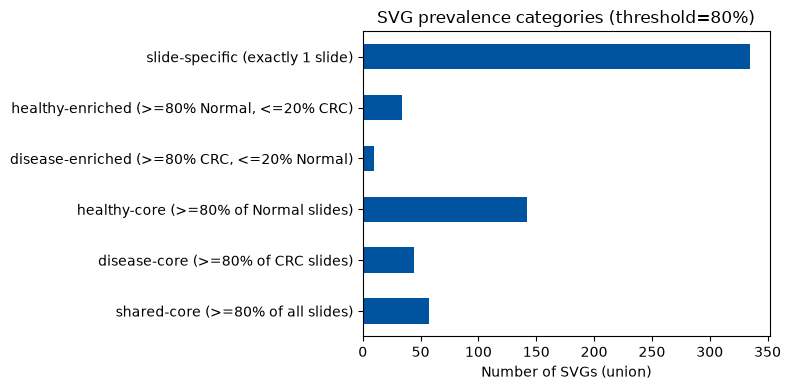

In [17]:
# Prevalence-threshold categories (condition-aware "UpSet" summary): a gene
# counts as belonging to a category if it's an SVG in >=80% of the relevant
# slide group. With only 2 Normal slides, ">=80% of healthy" means both.
PREVALENCE_THRESH = 0.8
n_crc = sum(c == "CRC" for c in conditions.values())
n_normal = sum(c == "Normal" for c in conditions.values())
crc_cols = [i for i, s in enumerate(sample_order) if conditions[s] == "CRC"]
normal_cols = [i for i, s in enumerate(sample_order) if conditions[s] == "Normal"]

frac_all = is_svg.mean(axis=1)
frac_crc = is_svg[:, crc_cols].mean(axis=1)
frac_normal = is_svg[:, normal_cols].mean(axis=1)
n_slides_hit = is_svg.sum(axis=1)

categories = {
    "shared-core (>=80% of all slides)": frac_all >= PREVALENCE_THRESH,
    "disease-core (>=80% of CRC slides)": frac_crc >= PREVALENCE_THRESH,
    "healthy-core (>=80% of Normal slides)": frac_normal >= PREVALENCE_THRESH,
    "disease-enriched (>=80% CRC, <=20% Normal)": (frac_crc >= PREVALENCE_THRESH) & (frac_normal <= 0.2),
    "healthy-enriched (>=80% Normal, <=20% CRC)": (frac_normal >= PREVALENCE_THRESH) & (frac_crc <= 0.2),
    "slide-specific (exactly 1 slide)": n_slides_hit == 1,
}
cat_counts = pd.Series({k: v.sum() for k, v in categories.items()})
print(cat_counts)

fig, ax = plt.subplots(figsize=(8, 4))
cat_counts.plot(kind="barh", ax=ax, color=pl.RWTH_CATEGORICAL[0])
ax.set_xlabel("Number of SVGs (union)")
ax.set_title(f"SVG prevalence categories (threshold={PREVALENCE_THRESH:.0%})")
plt.tight_layout()
plt.savefig("output/Nucleus_svg_Prevalence-threshold-categories.pdf")
plt.show()

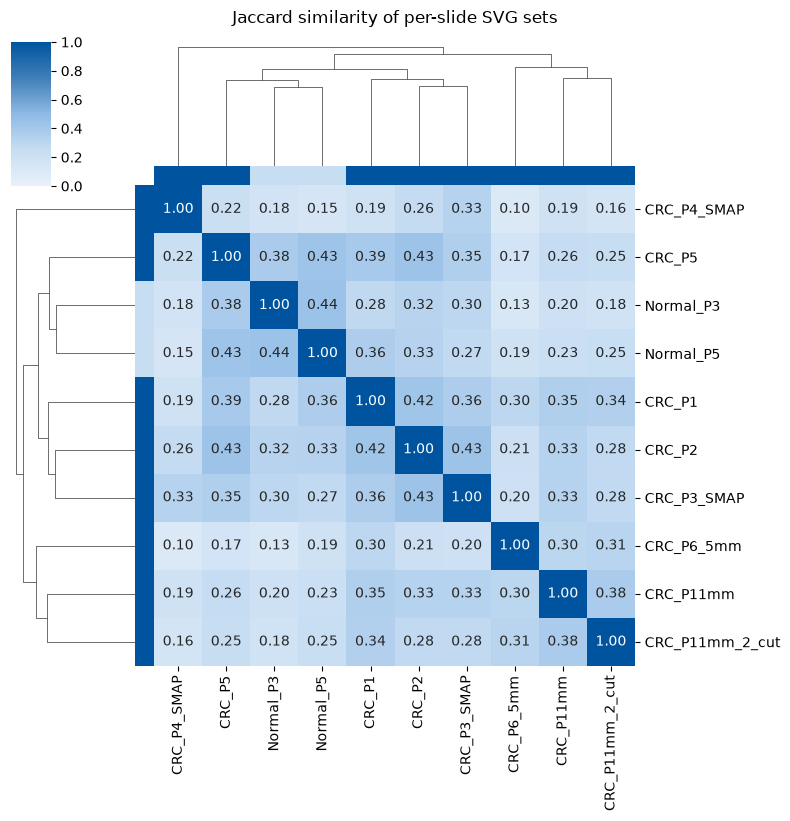

In [18]:
# Jaccard similarity between slides' SVG sets, with hierarchical clustering --
# slides clustering by condition (rather than by patient/batch/depth) supports a
# condition-associated SVG repertoire; a slide dissimilar to everyone else is
# worth investigating individually (c.f. CRC_P6_5mm's QC-driven low SVG count above)
jaccard_dist = pdist(is_svg.T, metric="jaccard")  # slides x slides, over the SVG union
jaccard_sim = 1 - squareform(jaccard_dist)
jaccard_df = pd.DataFrame(jaccard_sim, index=sample_order, columns=sample_order)

g = sns.clustermap(
    jaccard_df, cmap=pl.rwth_blue_cmap(), vmin=0, vmax=1,
    row_colors=[colors[conditions[s]] for s in sample_order],
    col_colors=[colors[conditions[s]] for s in sample_order],
    figsize=(8, 8), annot=True, fmt=".2f",
)
g.fig.suptitle("Jaccard similarity of per-slide SVG sets", y=1.02)
plt.savefig("output/Nucleus_svg_jaccard_similarity.pdf")
plt.show()

#### C. Healthy vs. diseased SVG repertoire
Distinguishes genes by *membership* (SVG in one condition but not the other) rather than raw counts.

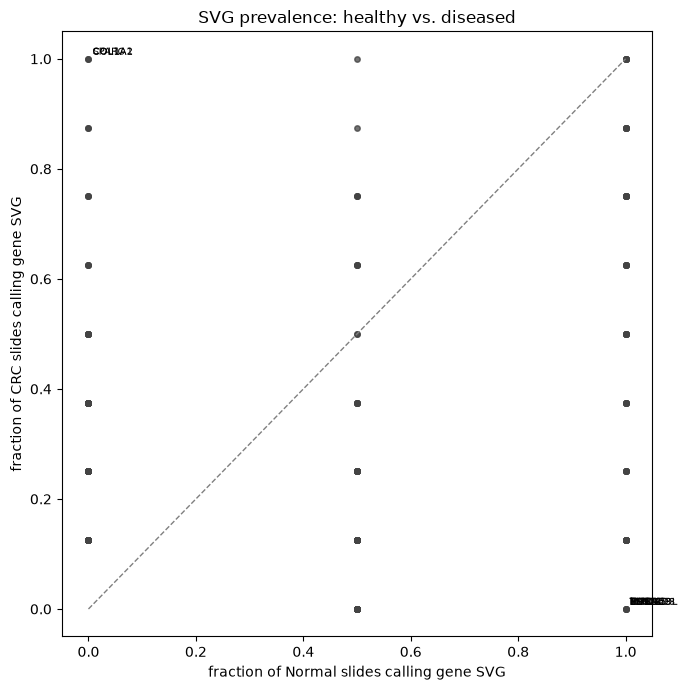

In [19]:
# prevalence scatter: p_H(g) vs p_D(g), one point per SVG in the union
prevalence_df = pd.DataFrame({
    "gene": svg_genes,
    "p_normal": frac_normal,
    "p_crc": frac_crc,
}).set_index("gene")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(prevalence_df["p_normal"], prevalence_df["p_crc"], s=15, alpha=0.5, color="#444444")
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
ax.set_xlabel("fraction of Normal slides calling gene SVG")
ax.set_ylabel("fraction of CRC slides calling gene SVG")
ax.set_title("SVG prevalence: healthy vs. diseased")

# label the most prevalence-divergent genes on each side of the diagonal
prevalence_df["diff"] = prevalence_df["p_crc"] - prevalence_df["p_normal"]
for _, row in prevalence_df.reindex(prevalence_df["diff"].abs().sort_values(ascending=False).index[:12]).iterrows():
    ax.annotate(row.name, (row["p_normal"], row["p_crc"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
plt.tight_layout()
plt.savefig("output/prevalence_scatter_healthy_vs_diseased_svg.pdf")
plt.show()

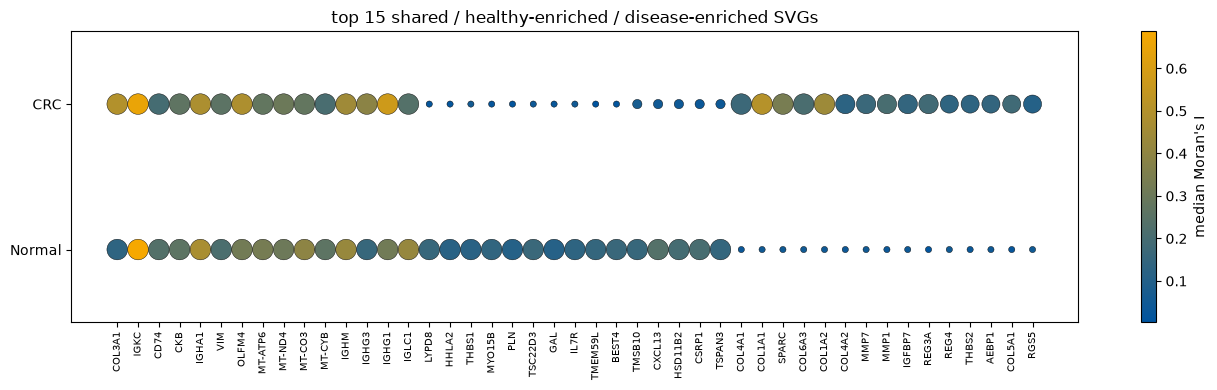

In [20]:
# dot plot of representative genes from each repertoire category -- top N by
# prevalence-difference (or overall prevalence for the shared set), avoids
# plotting all 539 genes at once
TOP_N = 15
disease_enriched_genes = prevalence_df.sort_values("diff", ascending=False).index[:TOP_N]
healthy_enriched_genes = prevalence_df.sort_values("diff", ascending=True).index[:TOP_N]
shared_genes = prevalence_df.loc[(prevalence_df["p_crc"] >= 0.8) & (prevalence_df["p_normal"] >= 0.8)] \
    .assign(mean_p=lambda d: (d["p_crc"] + d["p_normal"]) / 2) \
    .sort_values("mean_p", ascending=False).index[:TOP_N]

dot_genes = pd.Index(list(shared_genes) + list(healthy_enriched_genes) + list(disease_enriched_genes)).unique()
dot_rows = []
for gene in dot_genes:
    for cond, cols in [("Normal", normal_cols), ("CRC", crc_cols)]:
        gi = np.where(svg_genes == gene)[0][0]
        dot_rows.append({
            "gene": gene,
            "condition": cond,
            "prevalence": is_svg[gi, cols].mean(),
            "median_moranI": np.nanmedian(moranI[gi, cols]),
        })
dot_df = pd.DataFrame(dot_rows)

fig, ax = plt.subplots(figsize=(max(6, len(dot_genes) * 0.3), 4))
y_pos = {"Normal": 0, "CRC": 1}
sizes = 20 + dot_df["prevalence"] * 200
sc_plot = ax.scatter(
    [list(dot_genes).index(g) for g in dot_df["gene"]],
    [y_pos[c] for c in dot_df["condition"]],
    s=sizes, c=dot_df["median_moranI"], cmap=pl.rwth_blue_yellow_cmap(), edgecolors="black", linewidths=0.3,
)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Normal", "CRC"])
ax.set_xticks(range(len(dot_genes)))
ax.set_xticklabels(dot_genes, fontsize=7, rotation=90)
ax.set_ylim(-0.5, 1.5)
ax.set_title(f"top {TOP_N} shared / healthy-enriched / disease-enriched SVGs")
plt.colorbar(sc_plot, ax=ax, label="median Moran's I")
plt.tight_layout()
plt.savefig("output/Nucleus_dot plot of representative genes from each repertoire category.pdf")
plt.show()

#### D. Spatial expression panels for representative genes
A gene being an SVG doesn't say *where* its spatial pattern sits -- spot-check one gene per repertoire category on real tissue. Picks the top gene from each category found above; edit `GENES_TO_PLOT` to inspect others. Uses each slide's own `count_area_filtered_adata.h5ad` (not the backed combined file) since this needs actual expression values, not just the precomputed Moran's I summaries.

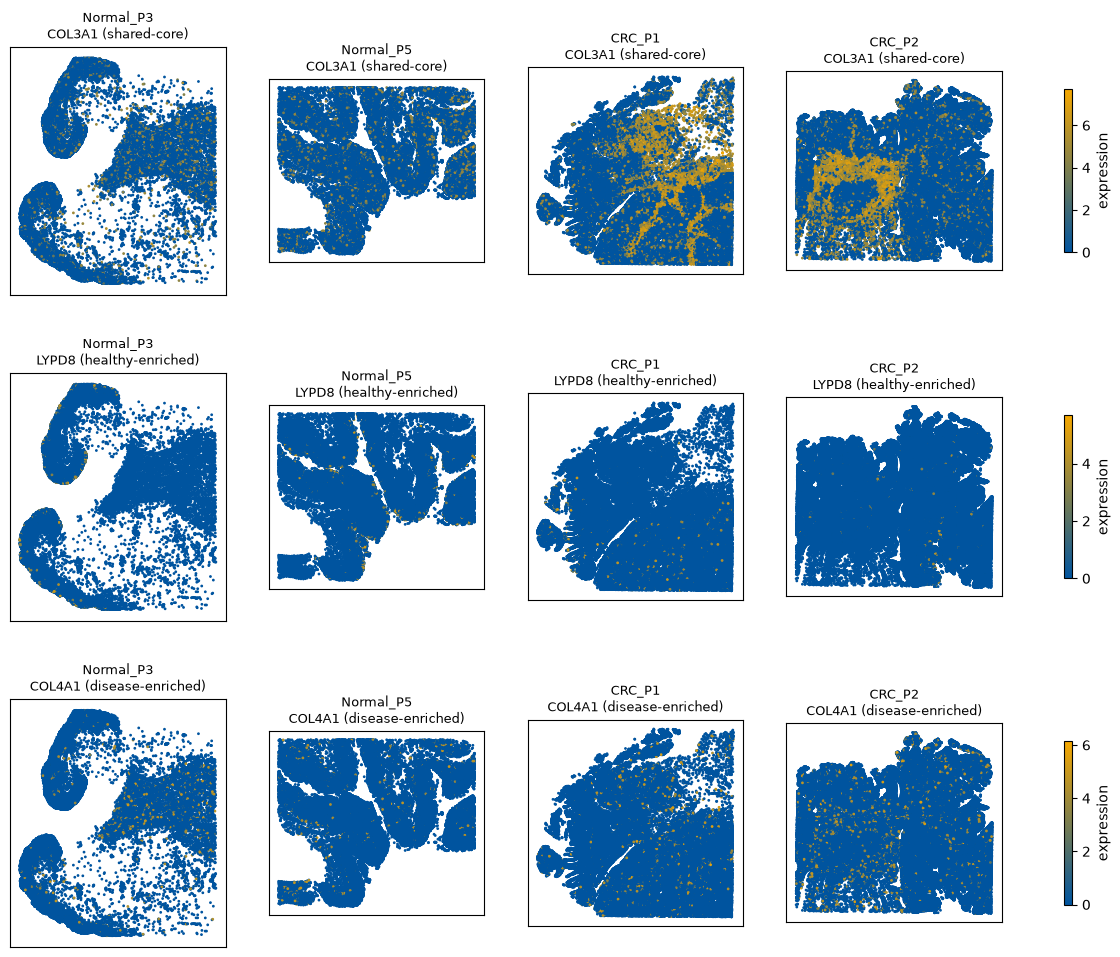

<Figure size 640x480 with 0 Axes>

In [21]:
GENES_TO_PLOT = {
    "shared-core": shared_genes[0],
    "healthy-enriched": healthy_enriched_genes[0],
    "disease-enriched": disease_enriched_genes[0],
}
PANEL_SLIDES = ["Normal_P3", "Normal_P5", "CRC_P1", "CRC_P2"]  # 2 healthy, 2 diseased

# Reads the merged combined/ copy (filtered per sample+gene) instead of each sample's
# own per-sample count_area_filtered_adata.h5ad, so per-sample copies are free to delete.
count_area_combined = sc.read_h5ad(basedir / "combined" / dir_custom_binning / "count_area_filtered_adata.h5ad", backed="r")

fig, axes = plt.subplots(len(GENES_TO_PLOT), len(PANEL_SLIDES), figsize=(4 * len(PANEL_SLIDES), 4 * len(GENES_TO_PLOT)))
for row, (label, gene) in enumerate(GENES_TO_PLOT.items()):
    gi = count_area_combined.var_names.get_loc(gene)
    # shared color scale across all 4 slides for this gene, not per-panel
    vals_per_slide = {}
    for sample_id in PANEL_SLIDES:
        mask = (count_area_combined.obs["Slide_ID"] == sample_id).to_numpy()
        sub = count_area_combined[mask, gi].to_memory()
        col_ = sub.X  # sliced column is a small sparse matrix even though the combined file is backed
        expr = np.asarray(col_.toarray() if hasattr(col_, "toarray") else col_).ravel()
        vals_per_slide[sample_id] = (np.asarray(sub.obsm["spatial"]), expr)
    vmax = max(expr.max() for _, expr in vals_per_slide.values())

    for col, sample_id in enumerate(PANEL_SLIDES):
        spatial, expr = vals_per_slide[sample_id]
        ax = axes[row, col]
        sc_plot = ax.scatter(spatial[:, 0], spatial[:, 1], c=expr, cmap=pl.rwth_blue_yellow_cmap(), s=1, vmin=0, vmax=vmax)
        ax.set_title(f"{sample_id}\n{gene} ({label})", fontsize=9)
        ax.invert_yaxis()
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc_plot, ax=axes[row, :].tolist(), shrink=0.6, label="expression")

plt.show()
plt.savefig("output/idk.pdf")
del count_area_combined

### Nuclei segmentation sanity check
Overlays the raw StarDist nuclei polygons on a 3x3 mosaic of spatially neighboring WSI patches, to visually confirm the two pipelines (histology patching and cell segmentation) agree on pixel coordinates.

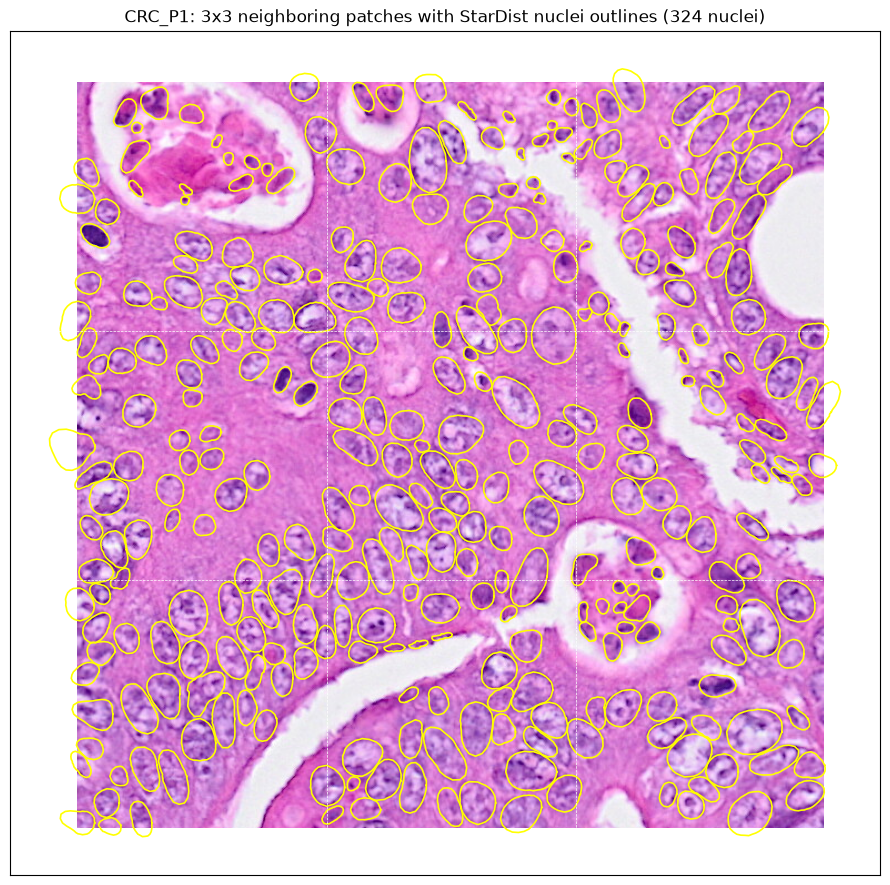

0

In [22]:
import pickle

sample_patches = "CRC_P1"
dir_patches = "01_preprocessing/unimodel/patches"
dir_cellseg = "01_preprocessing/cell_seg_stardist/002um"
PATCH_SIZE = 224          # px -- both the WSI patch grid spacing and each patch PNG's side length
MIN_NUCLEI_PER_PATCH = 5  # skip near-empty (background) 3x3 blocks

patch_meta = ad.read_h5ad(basedir / "combined" / dir_uni / "WSI_patch_metadata.h5ad", backed="r").obs
patch_meta = patch_meta[patch_meta["Slide_ID"] == sample_patches]

with open(basedir / sample_patches / dir_cellseg / "polys_FullSection.pckl", "rb") as f:
    polys_p1 = pickle.load(f)
nucleus_xy = polys_p1["points"][:, ::-1]  # stored as (row, col) -- flip to (x, y)

# Patches sit on an axis-aligned grid with PATCH_SIZE spacing but aren't necessarily
# contiguous (background-only tiles are dropped from unimodel/patches) -- integer grid
# indices from each patch's offset to the grid origin let us look up "the patch to the
# north/east/etc. of this one" and find an actually-contiguous 3x3 neighborhood.
gx = np.round((patch_meta["X"].to_numpy() - patch_meta["X"].min()) / PATCH_SIZE).astype(int)
gy = np.round((patch_meta["Y"].to_numpy() - patch_meta["Y"].min()) / PATCH_SIZE).astype(int)
grid = {(int(a), int(b)): (x, y, pid) for a, b, x, y, pid in
        zip(gx, gy, patch_meta["X"], patch_meta["Y"], patch_meta["Patch_ID"])}

def nuclei_count(x0, y0):
    x, y = nucleus_xy[:, 0], nucleus_xy[:, 1]
    return int(((x >= x0) & (x < x0 + PATCH_SIZE) & (y >= y0) & (y < y0 + PATCH_SIZE)).sum())

block = None
for (a, b) in grid:
    neighbors = [(a + i, b + j) for i in range(3) for j in range(3)]
    if not all(n in grid for n in neighbors):
        continue
    counts = [nuclei_count(*grid[n][:2]) for n in neighbors]
    if min(counts) >= MIN_NUCLEI_PER_PATCH:
        block = neighbors
        break
if block is None:
    raise RuntimeError(
        f"No 3x3 block of neighboring {sample_patches} patches with >= {MIN_NUCLEI_PER_PATCH} nuclei each was found."
    )

x_min = min(grid[n][0] for n in block)
y_min = min(grid[n][1] for n in block)

# Stitch the 9 patch PNGs into one mosaic, each placed by its actual grid offset
mosaic = np.zeros((3 * PATCH_SIZE, 3 * PATCH_SIZE, 3), dtype=np.float32)
for (a, b) in block:
    x, y, pid = grid[(a, b)]
    row, col = round((y - y_min) / PATCH_SIZE), round((x - x_min) / PATCH_SIZE)
    img = plt.imread(basedir / sample_patches / dir_patches / pid)
    mosaic[row * PATCH_SIZE:(row + 1) * PATCH_SIZE, col * PATCH_SIZE:(col + 1) * PATCH_SIZE] = img[..., :3]

# Only build polygon coordinates for nuclei actually inside this small region --
# polys_p1["coord"] has 1.26M entries total, far more than needed here.
in_region = (
    (nucleus_xy[:, 0] >= x_min) & (nucleus_xy[:, 0] < x_min + 3 * PATCH_SIZE) &
    (nucleus_xy[:, 1] >= y_min) & (nucleus_xy[:, 1] < y_min + 3 * PATCH_SIZE)
)
region_idx = np.where(in_region)[0]

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(mosaic)
for i in region_idx:
    rows, cols = polys_p1["coord"][i]  # (row=y, col=x), full-res pixel space, same frame as patch X/Y
    xs, ys = cols - x_min, rows - y_min
    ax.plot(np.append(xs, xs[0]), np.append(ys, ys[0]), color="#FFFF00", linewidth=1.2)
for k in (1, 2):
    ax.axhline(k * PATCH_SIZE, color="white", linewidth=0.5, linestyle="--")
    ax.axvline(k * PATCH_SIZE, color="white", linewidth=0.5, linestyle="--")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"{sample_patches}: 3x3 neighboring patches with StarDist nuclei outlines ({len(region_idx)} nuclei)")
plt.tight_layout()
plt.savefig("output/patches_with_nuclei.pdf")
plt.show()

del polys_p1, nucleus_xy
gc.collect()

### Nuclei-level label transfer spatial maps
Label transfer predictions only exist at 8um-grid resolution (`_grid_predictions.parquet`) or WSI-patch resolution -- never per nucleus -- so each nucleus below is colored by its *nearest* grid cell's predicted label (`lt.assign_nearest_grid_label`, built for exactly this). Compound labels are canonicalized to their top-2 dominant components (`canonical_top2`, defined above) so the legend doesn't explode with every 3+-way mixed label, same as the 8um-grid label-distribution bar chart. `CRC_P2` is the reference sample and has no prediction file of its own, so its ground-truth grid annotation (`grid_gt_008um`, also from above) stands in for both label-transfer columns below.

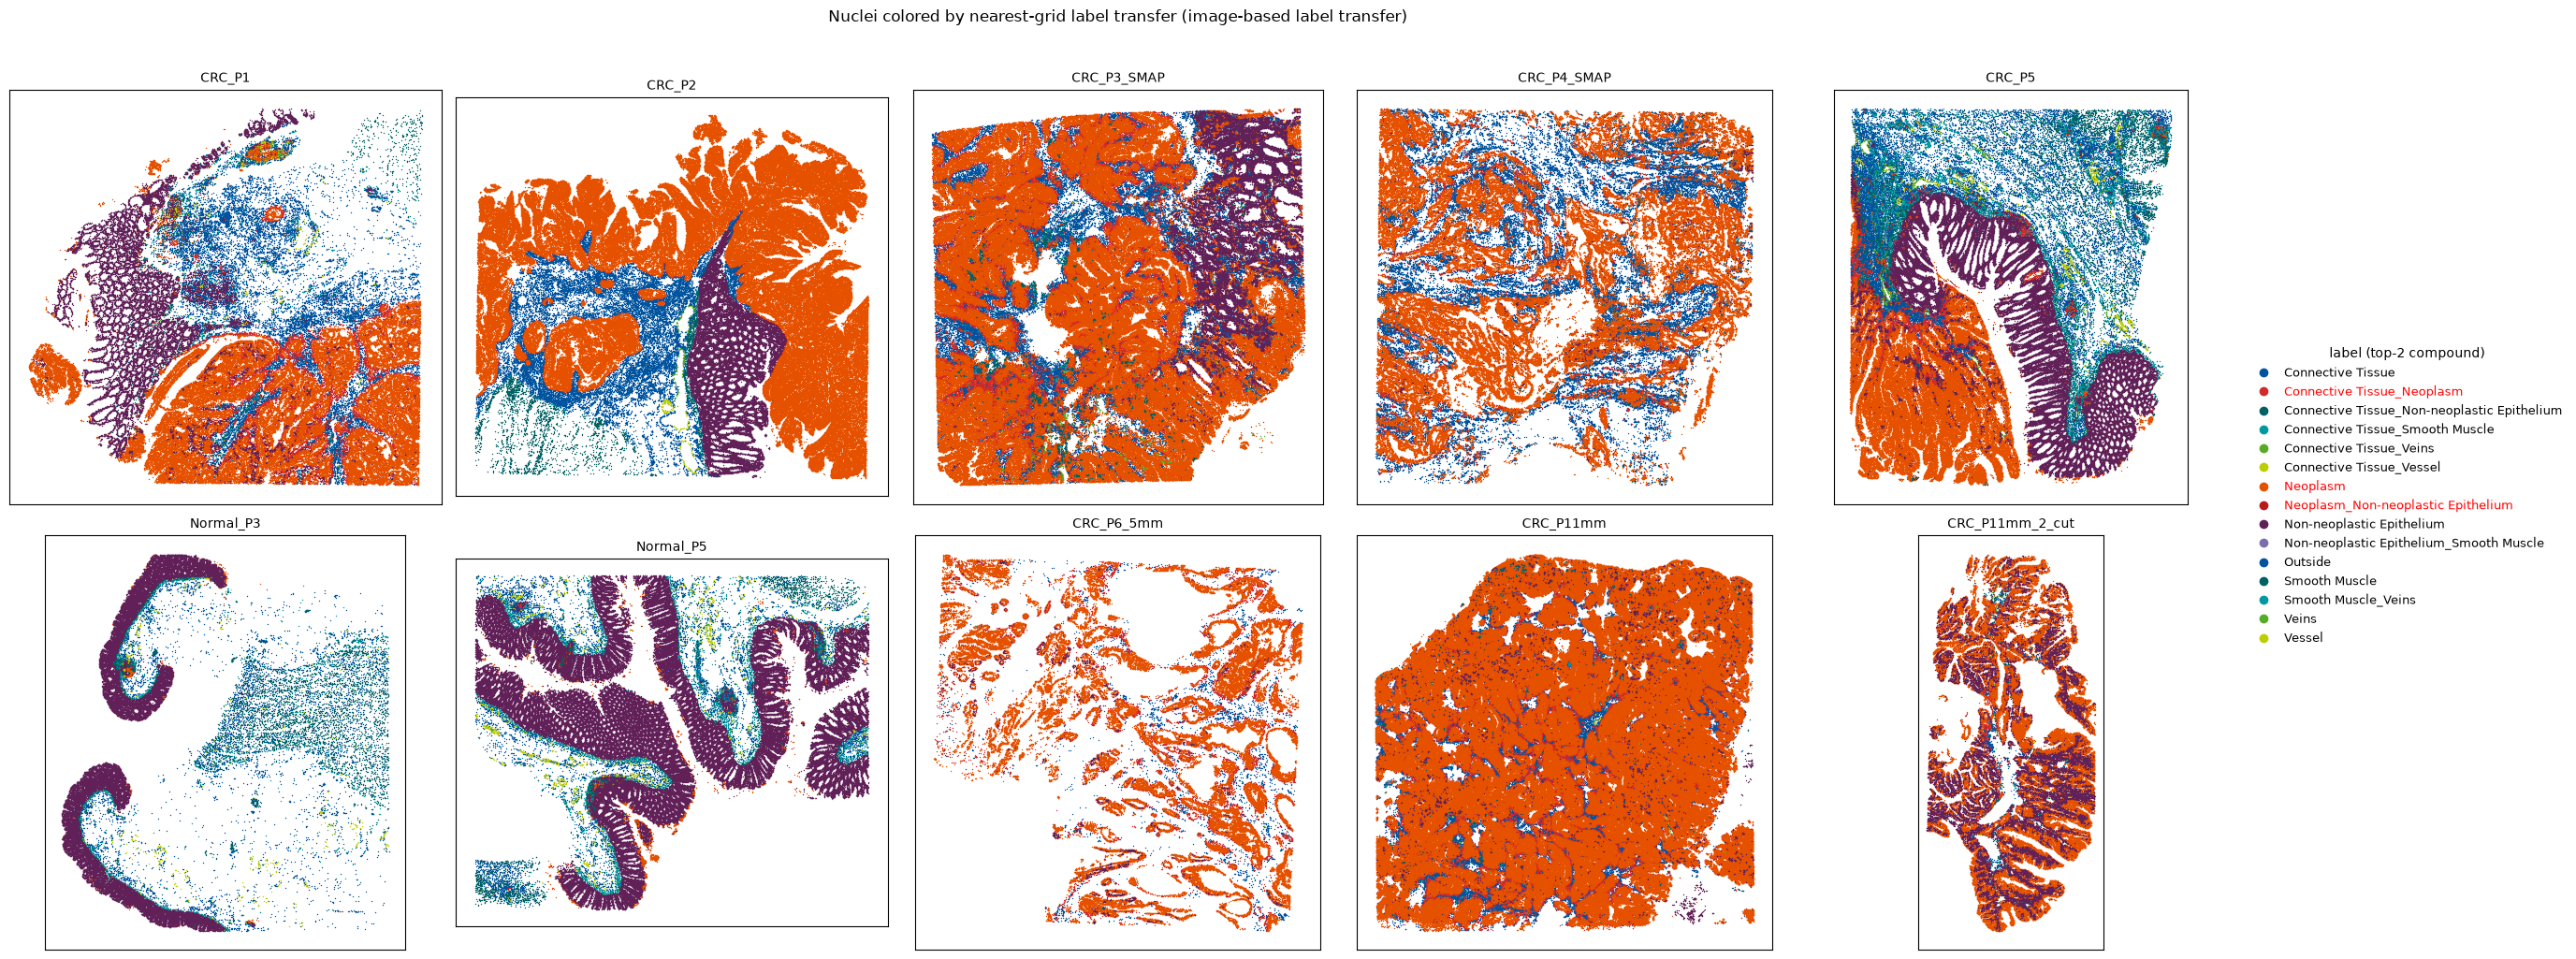

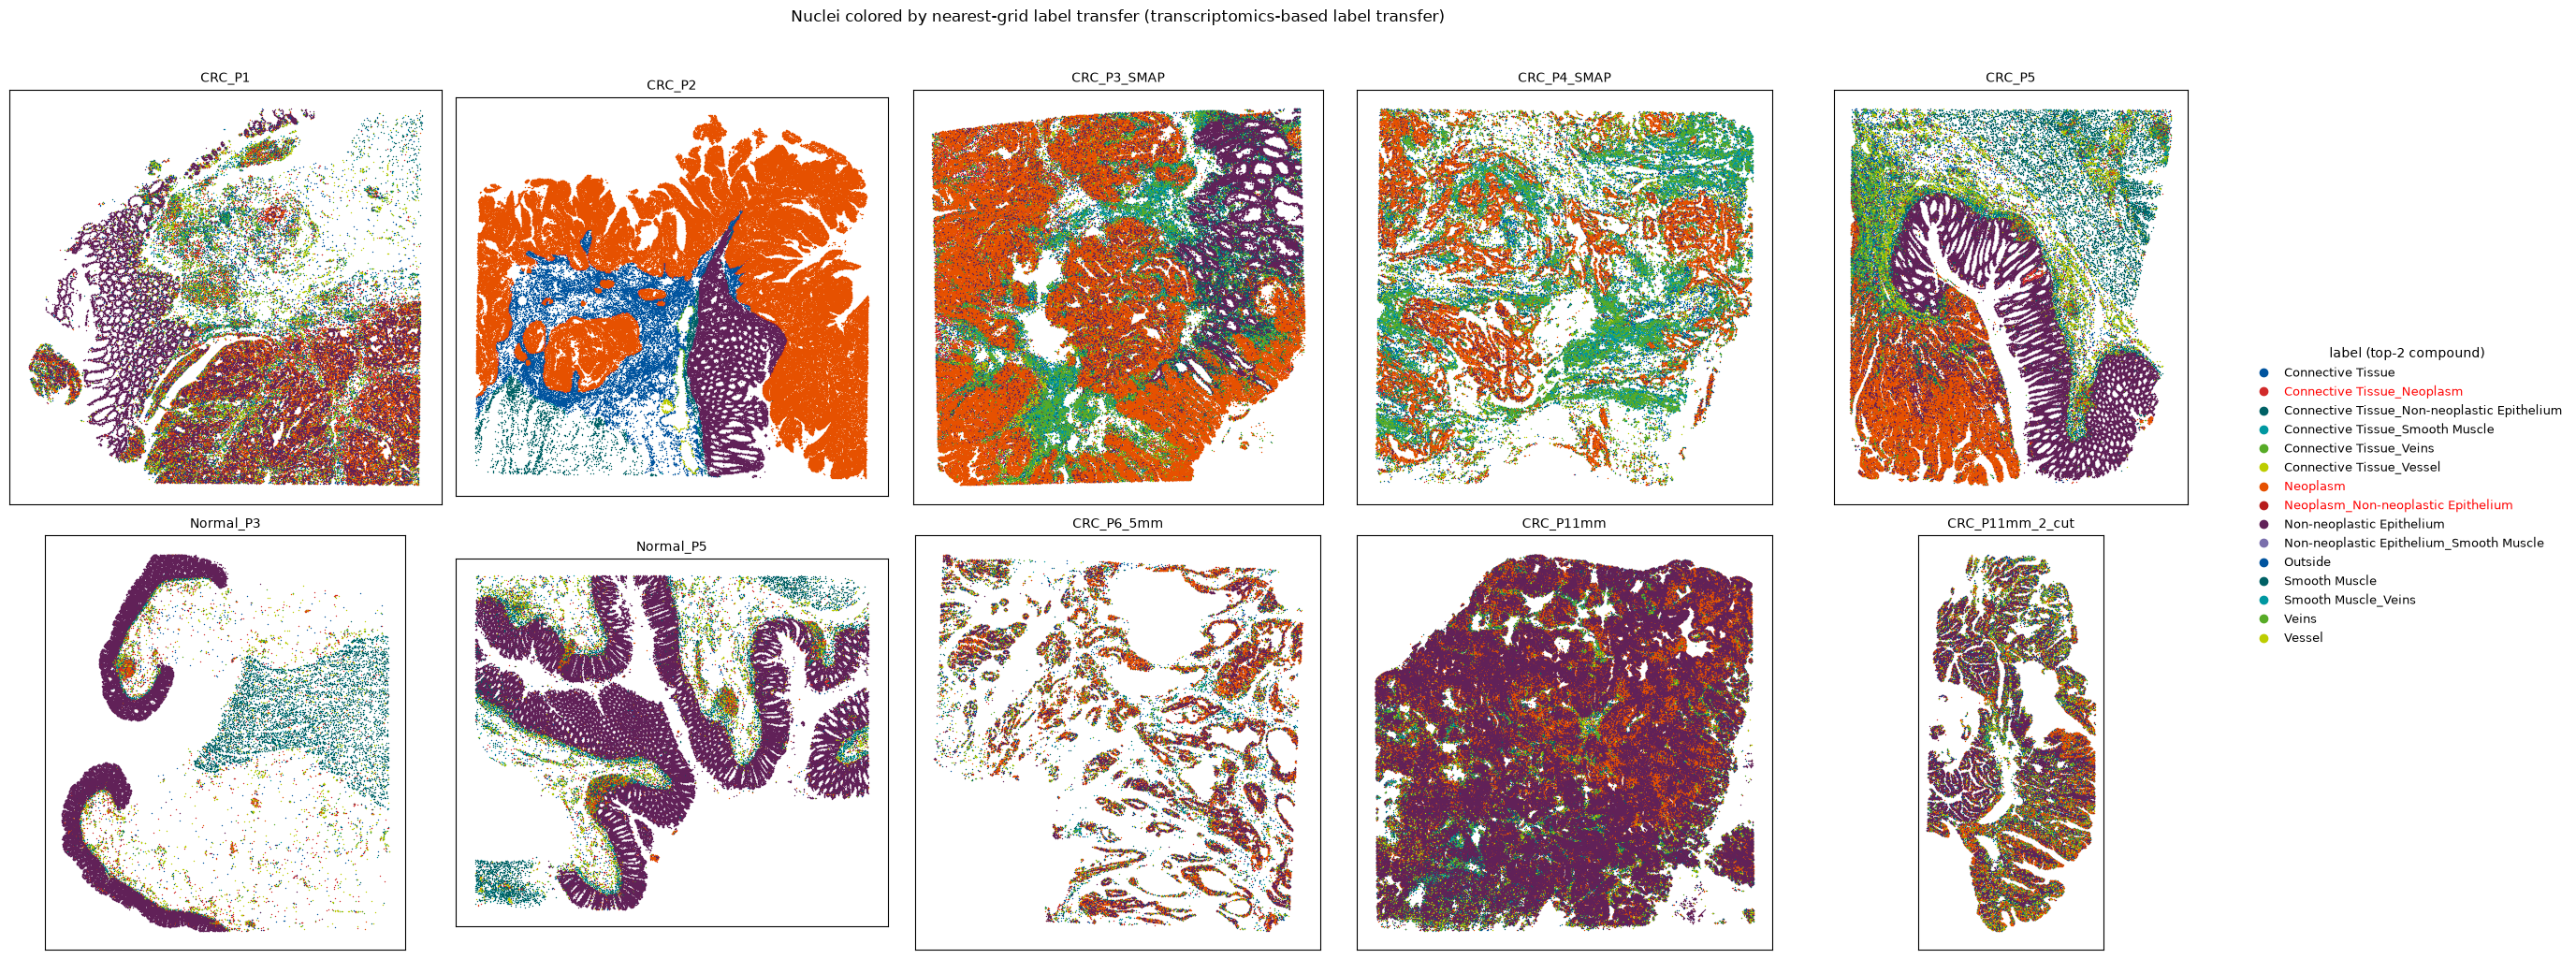

In [23]:
# Same red/orange-for-neoplasm scheme as the label-distribution bar chart above, but
# strictly excluding RWTH_CATEGORICAL's own orange/red/bordeaux entries from the
# non-neoplasm cycle -- the bar chart didn't filter those out, but "anything but
# red/orange for non-neoplastic tissue" only holds if they're excluded up front.
NEOPLASM_RED_SHADES = ["#D12A2A", "#E65100", "#B71C1C", "#FF5252", "#880E4F"]
NON_NEOPLASM_COLORS = [c for c in pl.RWTH_CATEGORICAL if c not in ("#F6A800", "#CC071E", "#A11035")]

def build_neoplasm_palette(labels):
    palette = {}
    neoplasm_idx = non_neoplasm_idx = 0
    for label in labels:
        if "neoplasm" in str(label).lower():
            palette[label] = NEOPLASM_RED_SHADES[neoplasm_idx % len(NEOPLASM_RED_SHADES)]
            neoplasm_idx += 1
        else:
            palette[label] = NON_NEOPLASM_COLORS[non_neoplasm_idx % len(NON_NEOPLASM_COLORS)]
            non_neoplasm_idx += 1
    return palette

LABEL_TRANSFER_COLUMNS = {
    "predicted_tissuetype_grid_image": "image-based label transfer",
    "predicted_tissuetype_grid_transcriptomics": "transcriptomics-based label transfer",
}

for label_col, plot_title in LABEL_TRANSFER_COLUMNS.items():
    coords_by_slide = {}
    labels_by_slide = {}
    for sample_id in samples:
        nuclei_mask = (trans_combined.obs["Slide_ID"] == sample_id).to_numpy()
        nuclei_coords = np.asarray(trans_combined.obsm["spatial"])[nuclei_mask]

        if sample_id == "CRC_P2":
            grid_df = grid_gt_008um.assign(label=canonical_top2(grid_gt_008um["annotation"]))
        else:
            pred_path = label_transfer_dir(sample_id) / f"{sample_id}_grid_predictions.parquet"
            grid_pred = pd.read_parquet(pred_path, columns=["pxl_col", "pxl_row", label_col])
            grid_df = grid_pred.assign(label=canonical_top2(grid_pred[label_col]))

        coords_by_slide[sample_id] = nuclei_coords
        labels_by_slide[sample_id] = lt.assign_nearest_grid_label(nuclei_coords, grid_df, label_col="label")

    all_labels = sorted(set(np.concatenate(list(labels_by_slide.values()))))
    palette = build_neoplasm_palette(all_labels)

    fig, axes = plt.subplots(2, 5, figsize=(24, 10))
    for ax, sample_id in zip(axes.flatten(), samples):
        coords, lbls = coords_by_slide[sample_id], labels_by_slide[sample_id]
        for lab in np.unique(lbls):
            mask = lbls == lab
            ax.scatter(coords[mask, 0], coords[mask, 1], s=1, color=palette[lab], linewidths=0)
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(sample_id, fontsize=10)

    handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=c, label=l) for l, c in palette.items()]
    leg = fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5),
                      fontsize=9, frameon=False, title="label (top-2 compound)")
    for text in leg.get_texts():
        if "neoplasm" in text.get_text().lower():
            text.set_color("red")

    fig.suptitle(f"Nuclei colored by nearest-grid label transfer ({plot_title})", y=1.02)
    fig.tight_layout()
    plt.savefig("output/label_transfer_plot.pdf")
    plt.show()